# FarmTech Solutions: previsão de rendimento de safra e descoberta de padrões

**Fase 5 do PBL. Machine Learning supervisionado e não supervisionado.**

**Integrantes**

| Nome | RM |
|---|---|
| Carlos Magnus Costa Amaral | RM573978 |
| Edemir Sufiatti | RM571375 |
| Georgia Mendes Rocha | RM573281 |
| Jocasta de Kacia Bortolacci | RM564730 |
| Marina Leme Soares | RM570461 |

**Tutora:** Nicolly Cândida Rodrigues de Souza
**Coordenador:** André Godoi Chiovato
**Data:** 30/08/2026

---

## Contexto

A FarmTech Solutions presta serviço de ciência de dados a uma fazenda de 200 hectares que produz múltiplas culturas. A demanda declarada é dupla:

1. Prever o rendimento de safra a partir de condições de solo e temperatura, via regressão supervisionada.
2. Explorar padrões de produtividade e identificar cenários discrepantes, via clusterização.

## Posição analítica deste trabalho

Este notebook não trata a demanda como um exercício de maximizar R². Trata como um problema de decisão: a fazenda quer saber se dados climáticos permitem antecipar produtividade a ponto de mudar decisões de plantio.

A leitura que a base sustenta é cautelosa, e a maior parte do trabalho a seguir existe para demonstrar por quê de forma auditável. O erro mais provável neste dataset não é escolher o algoritmo errado. É reportar um R² de 0.98 sem perceber que a variável cultura explica a maior parte do desempenho observado.

Essa leitura vale para a evidência preditiva disponível, não para uma afirmação mecanística. A seção 10 entrega a previsão de rendimento exigida pelo enunciado: os cinco modelos avaliados por validação agrupada por cenário climático, uma função de previsão reutilizável e cenários climáticos informados sem inventar datas, anos ou períodos.

A estrutura segue: diagnóstico da base antes de qualquer interpretação, depois exploração, depois clusterização, depois modelagem com baseline explícito, depois cenários de previsão, e por fim as limitações.

## 1. Setup e carga dos dados

Bibliotecas fixadas e semente global definida para favorecer a reprodutibilidade dos resultados no ambiente atual.

Nota documental: o enunciado da Fase 5 cita literalmente “Capítulo 13 — Modelagem de Dados com Regressão Supervisionada, da Fase 4”. O material oficial localizado na Biblioteca e usado como referência neste trabalho está identificado como “Fase 4 — Capítulo 11 — Modelagem de Dados com Regressão Supervisionada”. Registro a divergência apenas para rastreabilidade da fonte curricular utilizada.

In [1]:
# Manipulação de dados e álgebra
import pandas as pd
import numpy as np
import os

# Evita mensagem diagnóstica do loky sobre núcleos físicos em alguns ambientes Windows;
# afeta apenas a configuração de paralelismo, sem alterar dados, modelos ou métricas.
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

# Visualização
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Pré-processamento e pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Modelos supervisionados: cinco algoritmos de famílias distintas
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# Não supervisionado
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score

# Validação e métricas
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

# Semente única usada em todo o notebook
SEED = 42
np.random.seed(SEED)

# Padrão visual dos gráficos
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

print('Ambiente carregado.')
print('pandas', pd.__version__, '| numpy', np.__version__)

Ambiente carregado.
pandas 3.0.2 | numpy 2.4.4


In [2]:
# Carga do dataset fornecido no portal
df = pd.read_csv('crop_yield.csv')

# Renomeio para nomes curtos que preservam os rótulos e unidades declaradas
# no enunciado/CSV. As ressalvas de unidade estão documentadas na célula seguinte.
df.columns = [
    'cultura',
    'precipitacao_mm_dia',
    'umid_especifica_g_kg',
    'umid_relativa_pct',
    'temperatura_c',
    'rendimento'
]

# Blocos de colunas usados repetidamente
CLIMA = ['precipitacao_mm_dia', 'umid_especifica_g_kg', 'umid_relativa_pct', 'temperatura_c']
ALVO = 'rendimento'

print('Dimensões:', df.shape)
df.head(10)

Dimensões: (156, 6)


,cultura,precipitacao_mm_dia,umid_especifica_g_kg,umid_relativa_pct,temperatura_c,rendimento
0,"Cocoa, beans",2248.92,17.72,83.40,26.01,11560
1,"Cocoa, beans",1938.42,17.54,82.11,26.11,11253
2,"Cocoa, beans",2301.54,17.81,82.79,26.24,9456
3,"Cocoa, beans",2592.35,17.61,85.07,25.56,9321
4,"Cocoa, beans",2344.72,17.61,84.12,25.76,8800
5,"Cocoa, beans",2339.30,17.70,84.54,25.76,8850
6,"Cocoa, beans",2326.09,18.09,84.63,26.11,9003
7,"Cocoa, beans",2718.08,18.30,85.43,26.12,9880
8,"Cocoa, beans",2061.61,17.80,84.36,25.88,9201
9,"Cocoa, beans",1934.62,17.94,83.43,26.21,8300


### Dicionário de variáveis

| Coluna | Original | Descrição | Tipo |
|---|---|---|---|
| `cultura` | Crop | Nome da safra medida | Categórica nominal |
| `precipitacao_mm_dia` | Precipitation (mm day-1) | Precipitação na unidade declarada pelo enunciado/CSV | Numérica contínua |
| `umid_especifica_g_kg` | Specific Humidity at 2 Meters (g/kg) | Vapor de água por kg de ar seco a 2 m | Numérica contínua |
| `umid_relativa_pct` | Relative Humidity at 2 Meters (%) | Vapor de água como % do máximo suportado | Numérica contínua |
| `temperatura_c` | Temperature at 2 Meters (C) | Temperatura em ºC a 2 m do solo | Numérica contínua |
| `rendimento` | Yield | Rendimento da safra | Numérica contínua (alvo) |

Governança sobre a unidade do alvo: o enunciado descreve `Yield` como toneladas por hectare, mas os valores observados no CSV vão de 5.249 a 203.399, escala incompatível com a leitura literal em t/ha. A equipe consultou a tutoria, que informou que tanto manter os valores originais quanto realizar uma conversão é aceito, desde que a decisão seja tecnicamente justificada, documentada e aplicada de forma coerente. Este notebook preserva o valor original do CSV em `rendimento` durante a análise e a modelagem, não altera `crop_yield.csv` e adota apenas nas saídas operacionais a divisão por 10.000 para apresentar uma escala em t/ha. Essa conversão é uma decisão metodológica de apresentação motivada pela inconsistência percebida entre escala e unidade declarada; ela não comprova que a unidade original seja hg/ha nem que o arquivo tenha proveniência FAO/FAOSTAT. A rastreabilidade é mantida por tabelas com o valor original e o valor convertido.

Governança sobre precipitação: o enunciado/CSV declara `Precipitation (mm day-1)`, e o nome interno `precipitacao_mm_dia` reproduz essa unidade declarada. Porém, os valores observados estão na ordem de milhares, o que torna a interpretação literal em mm/dia questionável. O arquivo não contém metadados suficientes para concluir se a variável representa acumulado, média, outra janela temporal ou outra unidade. Por isso, a coluna original é preservada, nenhuma conversão de precipitação é aplicada e a unidade declarada não é tratada como validada externamente.

In [3]:
# Verificação de integridade antes de qualquer análise
print('=== TIPOS ===')
print(df.dtypes.to_string())

print('\n=== VALORES AUSENTES ===')
print(df.isna().sum().to_string())

print('\n=== LINHAS DUPLICADAS ===')
print(df.duplicated().sum())

print('\n=== CARDINALIDADE DA CATEGÓRICA ===')
print(df['cultura'].value_counts().to_string())

=== TIPOS ===
cultura                     str
precipitacao_mm_dia     float64
umid_especifica_g_kg    float64
umid_relativa_pct       float64
temperatura_c           float64
rendimento                int64

=== VALORES AUSENTES ===
cultura                 0
precipitacao_mm_dia     0
umid_especifica_g_kg    0
umid_relativa_pct       0
temperatura_c           0
rendimento              0

=== LINHAS DUPLICADAS ===
0

=== CARDINALIDADE DA CATEGÓRICA ===
cultura
Cocoa, beans       39
Oil palm fruit     39
Rice, paddy        39
Rubber, natural    39


Base íntegra sob os critérios convencionais: sem ausentes, sem duplicatas exatas, tipagem correta, e quatro culturas perfeitamente balanceadas com 39 registros cada.

O balanceamento exato entre culturas merece verificação estrutural e motiva a análise da organização dos registros na próxima seção.

## 2. Diagnóstico estrutural

Esta seção antecede a análise exploratória por decisão deliberada. A pergunta aqui não é o que os dados dizem, e sim o que os dados são. Se a estrutura da base introduzir dependência entre observações, a estratégia de validação deve respeitá-la para evitar métricas excessivamente otimistas.

Hipótese a testar: dado que cada cultura tem exatamente 39 registros, é possível que as variáveis climáticas sejam as mesmas nas quatro culturas, o que indicaria um mesmo conjunto de vetores climáticos replicado.

In [4]:
# Teste: as observações climáticas se repetem entre culturas?
# Comparo, linha a linha, os blocos climáticos de cada cultura contra o primeiro bloco.
blocos = {nome: grupo[CLIMA].reset_index(drop=True) for nome, grupo in df.groupby('cultura')}
culturas = list(blocos.keys())
referencia = blocos[culturas[0]]

print(f'Bloco de referência: {culturas[0]}\n')
for nome in culturas[1:]:
    identico = np.allclose(blocos[nome].values, referencia.values)
    print(f'{nome:20s} climaticamente idêntico à referência: {identico}')

# Identificador de cenário climático: baseado exclusivamente nas quatro variáveis climáticas.
df['cenario_climatico'] = df.groupby(CLIMA, sort=False).ngroup().astype(int)

combinacoes_unicas = df[CLIMA].drop_duplicates().shape[0]
grupos_cenario = df.groupby('cenario_climatico')
tamanho_grupos = grupos_cenario.size()
culturas_por_grupo = grupos_cenario['cultura'].nunique()
culturas_completas = grupos_cenario['cultura'].agg(lambda s: set(s) == set(culturas))

validacao_cenarios = pd.DataFrame({
    'valor_observado': [
        df['cenario_climatico'].nunique(),
        int(tamanho_grupos.min()),
        int(tamanho_grupos.max()),
        int(culturas_por_grupo.min()),
        int(culturas_por_grupo.max()),
        bool(tamanho_grupos.eq(4).all()),
        bool(culturas_completas.all()),
    ]
}, index=[
    'cenários climáticos distintos',
    'mínimo de linhas por cenário',
    'máximo de linhas por cenário',
    'mínimo de culturas por cenário',
    'máximo de culturas por cenário',
    'todos os cenários têm 4 linhas',
    'todos os cenários contêm as 4 culturas',
])

assert combinacoes_unicas == 39
assert df['cenario_climatico'].nunique() == 39
assert tamanho_grupos.eq(4).all()
assert culturas_por_grupo.eq(len(culturas)).all()
assert culturas_completas.all()

print(f'\nLinhas na base: {len(df)}')
print(f'Combinações climáticas únicas: {combinacoes_unicas}')
print(f'Cenários climáticos usados como grupos: {df["cenario_climatico"].nunique()}')
display(validacao_cenarios)

Bloco de referência: Cocoa, beans

Oil palm fruit       climaticamente idêntico à referência: True
Rice, paddy          climaticamente idêntico à referência: True
Rubber, natural      climaticamente idêntico à referência: True

Linhas na base: 156
Combinações climáticas únicas: 39
Cenários climáticos usados como grupos: 39


,valor_observado
cenários climáticos distintos,39
mínimo de linhas por cenário,4
máximo de linhas por cenário,4
mínimo de culturas por cenário,4
máximo de culturas por cenário,4
todos os cenários têm 4 linhas,True
todos os cenários contêm as 4 culturas,True


### Achado 1: a base tem 156 observações agrupadas em 39 cenários climáticos distintos

As quatro culturas compartilham exatamente o mesmo vetor climático em cada posição correspondente do arquivo. A base contém 39 combinações climáticas únicas, replicadas quatro vezes, cada réplica associada ao rendimento de uma cultura diferente. O dataset não informa a localização das observações nem permite determinar a cobertura espacial da base.

Criei `cenario_climatico` exclusivamente a partir das quatro variáveis climáticas: precipitação, umidade específica, umidade relativa e temperatura. Esse identificador serve só para validação agrupada; ele não tem significado temporal e não entra como feature dos modelos.

Três verificações estruturais foram impostas por `assert`: existem exatamente 39 grupos, cada grupo possui exatamente 4 linhas e cada grupo contém as 4 culturas.

Três consequências diretas:

**Sobre validação.** Uma validação por linha pode colocar no teste uma condição climática que já apareceu no treino sob outra cultura. Não é vazamento do alvo, mas cria dependência estrutural entre treino e teste, pois o mesmo cenário climático pode aparecer nos dois conjuntos se a divisão for feita por linha. A avaliação principal precisa manter as quatro linhas de cada cenário sempre juntas.

**Sobre volume de cenários.** O arquivo contém 156 linhas agrupadas em 39 cenários climáticos distintos. Essa quantidade de cenários é limitada para avaliar relações clima-rendimento com quatro preditores. A ausência de ganho preditivo neste dataset não prova ausência de associação clima-rendimento em geral.

**Sobre a natureza do problema.** O que separa as culturas não é clima, porque o clima é idêntico dentro de cada cenário. É a identidade da cultura. Isso define o desenho experimental adotado na seção 6.

In [5]:
# Índice ordinal do arquivo dentro de cada cultura.
# Não é data, ano nem período temporal; serve apenas para auditar dependência da ordem das linhas.
df['indice_registro'] = df.groupby('cultura').cumcount()

print('Correlação de Pearson entre o índice ordinal da linha e cada variável\n')
print('Clima (idêntico para todas as culturas):')
clima_ref = df[df['cultura'] == culturas[0]].reset_index(drop=True)
for col in CLIMA:
    r = np.corrcoef(clima_ref['indice_registro'], clima_ref[col])[0, 1]
    print(f'  {col:24s} r = {r:+.3f}')

print('\nRendimento, por cultura:')
for nome, grupo in df.groupby('cultura'):
    g = grupo.reset_index(drop=True)
    r = np.corrcoef(g['indice_registro'], g['rendimento'])[0, 1]
    print(f'  {nome:20s} r = {r:+.3f}')

Correlação de Pearson entre o índice ordinal da linha e cada variável

Clima (idêntico para todas as culturas):
  precipitacao_mm_dia      r = +0.419
  umid_especifica_g_kg     r = +0.802
  umid_relativa_pct        r = +0.218
  temperatura_c            r = +0.663

Rendimento, por cultura:
  Cocoa, beans         r = +0.101
  Oil palm fruit       r = +0.498
  Rice, paddy          r = +0.912
  Rubber, natural      r = -0.358


### Achado 2: a ordem das linhas não comprova temporalidade

O índice ordinal da linha correlaciona fortemente com umidade específica (r = +0.80) e temperatura (r = +0.66). Isso mostra que o arquivo possui uma ordenação interna estruturada, mas o dataset não contém coluna de data, ano ou metadado que comprove cronologia.

Por isso, a ordem das linhas não será tratada como série temporal. Não é possível afirmar que os registros representam anos, décadas, passado, futuro, aquecimento progressivo ou qualquer evolução cronológica.

A coluna `indice_registro` é mantida apenas como variável diagnóstica da posição no arquivo. Ela não entra como preditor em nenhum modelo e não sustenta conclusões sobre próxima safra ou validação temporal.

## 3. Análise exploratória

Com a estrutura da base compreendida, a exploração passa a ter um propósito definido: dimensionar quanto da variância do rendimento vive entre culturas e quanto vive dentro de cada cultura. Só a segunda parcela é potencialmente associável às variáveis climáticas disponíveis.

In [6]:
# Estatísticas descritivas das variáveis climáticas.
# Uso apenas os 39 registros únicos, já que replicar quatro vezes não adiciona
# informação e distorceria qualquer erro padrão calculado sobre a amostra.
desc_clima = clima_ref[CLIMA].describe().T
desc_clima['cv'] = (desc_clima['std'] / desc_clima['mean']).round(4)
desc_clima['amplitude'] = desc_clima['max'] - desc_clima['min']
display(desc_clima.round(2))

,count,mean,std,min,25%,50%,75%,max,cv,amplitude
precipitacao_mm_dia,39.0,2486.50,292.30,1934.62,2305.75,2424.55,2705.21,3085.79,0.12,1151.17
umid_especifica_g_kg,39.0,18.20,0.30,17.54,18.06,18.27,18.39,18.70,0.02,1.16
umid_relativa_pct,39.0,84.74,1.01,82.11,84.18,84.85,85.50,86.10,0.01,3.99
temperatura_c,39.0,26.18,0.26,25.56,26.02,26.13,26.29,26.81,0.01,1.25


In [7]:
# Estatísticas do alvo por cultura. O coeficiente de variação permite comparar
# dispersão entre culturas que operam em escalas absolutas muito diferentes.
desc_alvo = df.groupby('cultura')['rendimento'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])
desc_alvo['cv'] = (desc_alvo['std'] / desc_alvo['mean']).round(3)
display(desc_alvo.round(1))

# Decomposição da variância total do alvo em componente entre culturas e dentro delas
media_geral = df['rendimento'].mean()
medias_cultura = df.groupby('cultura')['rendimento'].transform('mean')

sq_total = ((df['rendimento'] - media_geral) ** 2).sum()
sq_entre = ((medias_cultura - media_geral) ** 2).sum()
sq_dentro = ((df['rendimento'] - medias_cultura) ** 2).sum()

print(f'\nDecomposição da variância do rendimento')
print(f'  Entre culturas : {sq_entre / sq_total:6.2%}')
print(f'  Dentro delas   : {sq_dentro / sq_total:6.2%}')

,count,mean,std,min,median,max,cv
cultura,,,,,,,
"Cocoa, beans",39,8883.1,1745.0,5765,8848.0,13056,0.2
Oil palm fruit,39,175804.7,14919.9,142425,175629.0,203399,0.1
"Rice, paddy",39,32099.7,4789.9,24686,31101.0,42550,0.1
"Rubber, natural",39,7824.9,1600.3,5249,7817.0,10285,0.2



Decomposição da variância do rendimento
  Entre culturas : 98.76%
  Dentro delas   :  1.24%


### Achado 3: 98,8% da variância do rendimento é entre culturas

A partição da soma de quadrados é o número mais importante deste notebook. Saber qual é a cultura explica 98,8% da variação do rendimento. As demais fontes de variação não identificadas pela cultura, incluindo clima, manejo e variação residual, disputam os 1,2% remanescentes.

Isso estabelece um referencial forte: um modelo que utiliza apenas a cultura já explica grande parte da variabilidade total observada. Um modelo que só reproduza a média de cada cultura já captura 98,8%. Qualquer R² próximo de 0.99 reportado adiante deve ser lido contra esse referencial, não contra zero.

Os coeficientes de variação intra-cultura são baixos e semelhantes: dendê 0.085, arroz 0.149, cacau 0.196, borracha 0.205. As culturas são individualmente estáveis. O que as separa é o patamar, não a volatilidade.

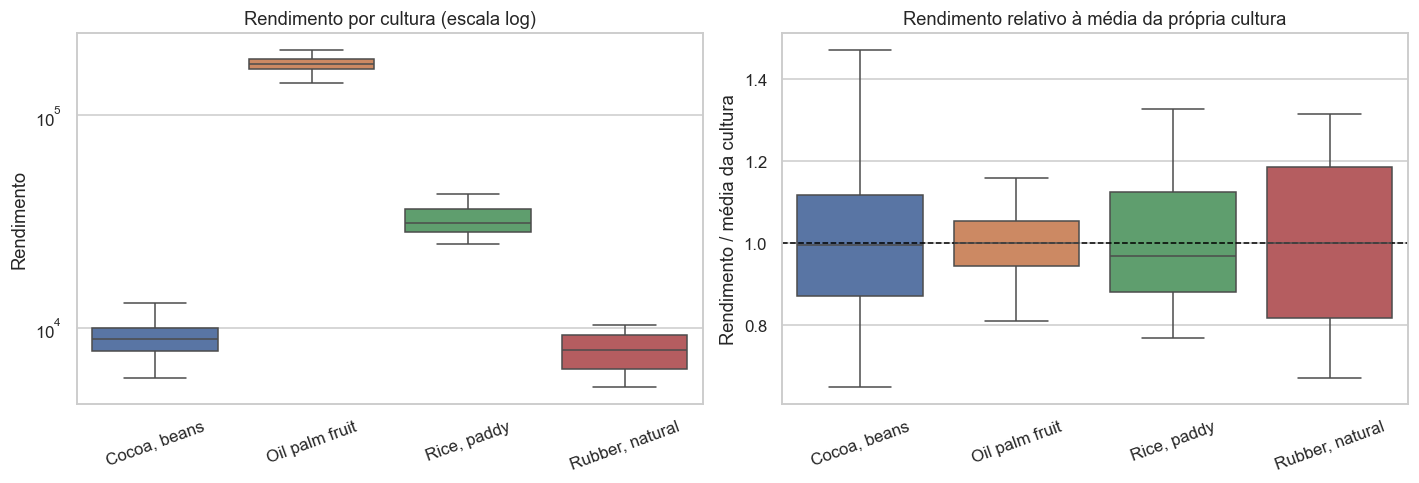

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Escala logarítmica é obrigatória aqui: dendê rende ~22x mais que borracha,
# e em escala linear as outras três culturas colapsam em uma faixa ilegível.
sns.boxplot(data=df, x='cultura', y='rendimento', ax=axes[0], hue='cultura', legend=False)
axes[0].set_yscale('log')
axes[0].set_title('Rendimento por cultura (escala log)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Rendimento')
axes[0].tick_params(axis='x', rotation=20)

# Normalizando cada cultura pela própria média, a comparação de dispersão fica válida
df['rend_rel'] = df['rendimento'] / df.groupby('cultura')['rendimento'].transform('mean')
sns.boxplot(data=df, x='cultura', y='rend_rel', ax=axes[1], hue='cultura', legend=False)
axes[1].axhline(1.0, color='black', ls='--', lw=1)
axes[1].set_title('Rendimento relativo à média da própria cultura')
axes[1].set_xlabel('')
axes[1].set_ylabel('Rendimento / média da cultura')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

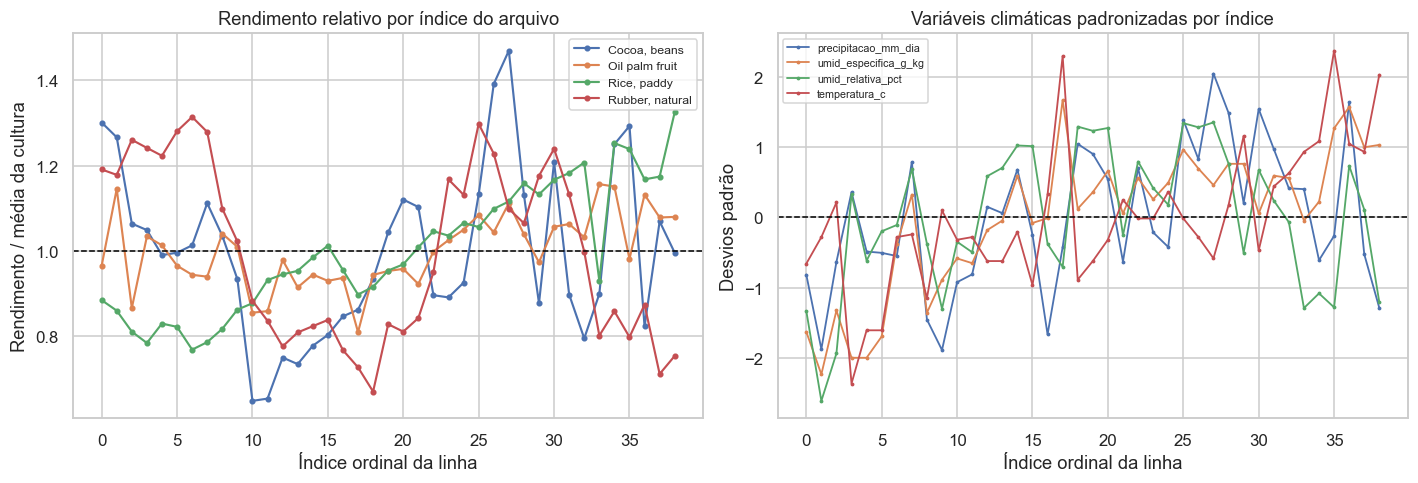

In [9]:
# Comportamento do rendimento ao longo do índice do arquivo, normalizado por cultura.
# Normalizar é o que torna as quatro séries comparáveis no mesmo eixo.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for nome, grupo in df.groupby('cultura'):
    g = grupo.sort_values('indice_registro')
    axes[0].plot(g['indice_registro'], g['rend_rel'], marker='o', ms=3, lw=1.4, label=nome)
axes[0].axhline(1.0, color='black', ls='--', lw=1)
axes[0].set_title('Rendimento relativo por índice do arquivo')
axes[0].set_xlabel('Índice ordinal da linha')
axes[0].set_ylabel('Rendimento / média da cultura')
axes[0].legend(fontsize=8)

# Clima padronizado no mesmo eixo, para visualizar padrões associados à ordem do arquivo
clima_pad = (clima_ref[CLIMA] - clima_ref[CLIMA].mean()) / clima_ref[CLIMA].std()
for col in CLIMA:
    axes[1].plot(clima_ref['indice_registro'], clima_pad[col], marker='.', ms=3, lw=1.2, label=col)
axes[1].axhline(0, color='black', ls='--', lw=1)
axes[1].set_title('Variáveis climáticas padronizadas por índice')
axes[1].set_xlabel('Índice ordinal da linha')
axes[1].set_ylabel('Desvios padrão')
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

Os dois painéis mostram que algumas variáveis variam de forma organizada ao longo do índice do arquivo. Essa leitura é apenas estrutural: sem data, ano ou metadado temporal, não se pode afirmar que arroz subiu ao longo do tempo nem que as variáveis climáticas evoluíram cronologicamente.

A seção 4 usa esse padrão somente como hipótese exploratória de sensibilidade à ordem das linhas, sem tratá-lo como evidência temporal.

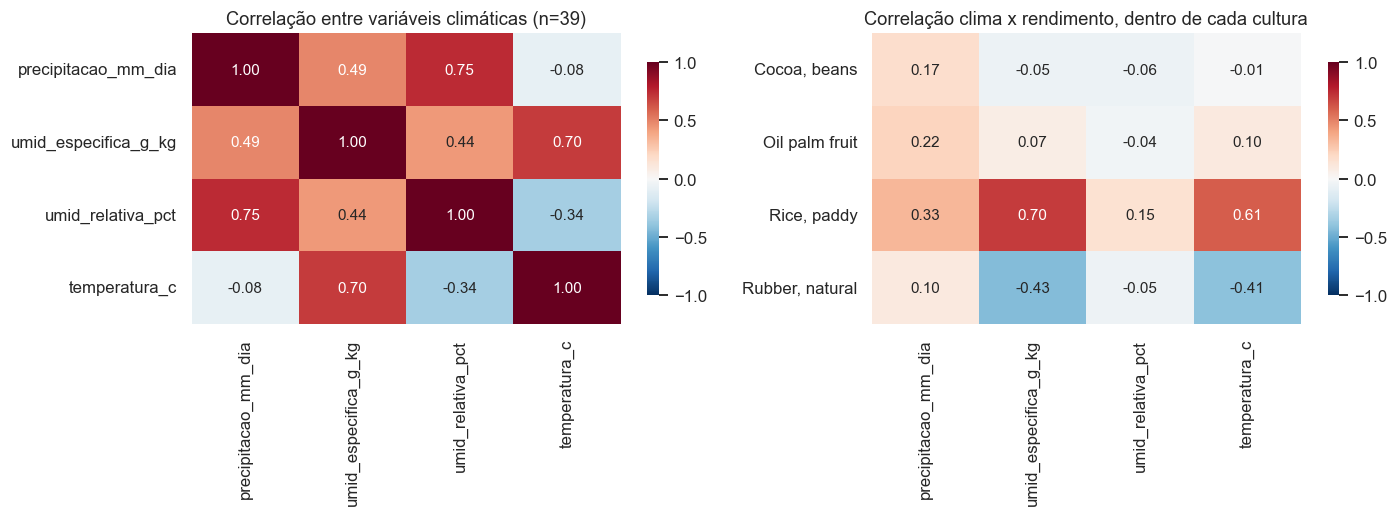

Correlação clima x rendimento agrupando todas as culturas (n=156):
precipitacao_mm_dia     0.0188
umid_especifica_g_kg    0.0127
umid_relativa_pct       0.0000
temperatura_c           0.0130


In [10]:
# Matriz de correlação. Uso apenas os 39 registros climáticos únicos para as
# correlações entre variáveis de clima, evitando inflar artificialmente a amostra.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

corr_clima = clima_ref[CLIMA].corr()
sns.heatmap(corr_clima, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Correlação entre variáveis climáticas (n=39)')

# Correlação clima x rendimento calculada dentro de cada cultura
linhas = []
for nome, grupo in df.groupby('cultura'):
    linhas.append(grupo[CLIMA + ['rendimento']].corr()['rendimento'].drop('rendimento').rename(nome))
corr_intra = pd.DataFrame(linhas)

sns.heatmap(corr_intra, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Correlação clima x rendimento, dentro de cada cultura')

plt.tight_layout()
plt.show()

print('Correlação clima x rendimento agrupando todas as culturas (n=156):')
print(df[CLIMA + ['rendimento']].corr()['rendimento'].drop('rendimento').round(4).to_string())

### Achado 4: a correlação global clima-rendimento é próxima de zero

Agrupando as quatro culturas, nenhuma variável climática passa de r = 0.019 com o rendimento. Isso não significa que clima seja irrelevante. Significa que a variância entre culturas, que o clima não diferencia porque é idêntico entre elas, domina o cálculo.

Separando por cultura, o quadro muda e fica heterogêneo:

- Arroz: umidade específica r = +0.70, temperatura r = +0.61. Sinal forte.
- Borracha: umidade específica r = -0.43, temperatura r = -0.41. Sinal moderado e de direção oposta.
- Cacau e dendê: todos os coeficientes abaixo de 0.23 em módulo, sem padrão consistente entre culturas.

Duas culturas com sinal em direções contrárias para as mesmas variáveis não é um resultado que sustente uma regra agronômica. É também um alerta de que a fonte comum da correlação pode estar associada à ordem do arquivo, e não ao clima.

Sobre a multicolinearidade entre preditores: precipitação e umidade relativa correlacionam a 0.75, umidade específica e temperatura a 0.70. Isso desestabiliza coeficientes de regressão linear e torna a leitura individual de cada coeficiente pouco confiável, embora não prejudique a capacidade preditiva agregada.

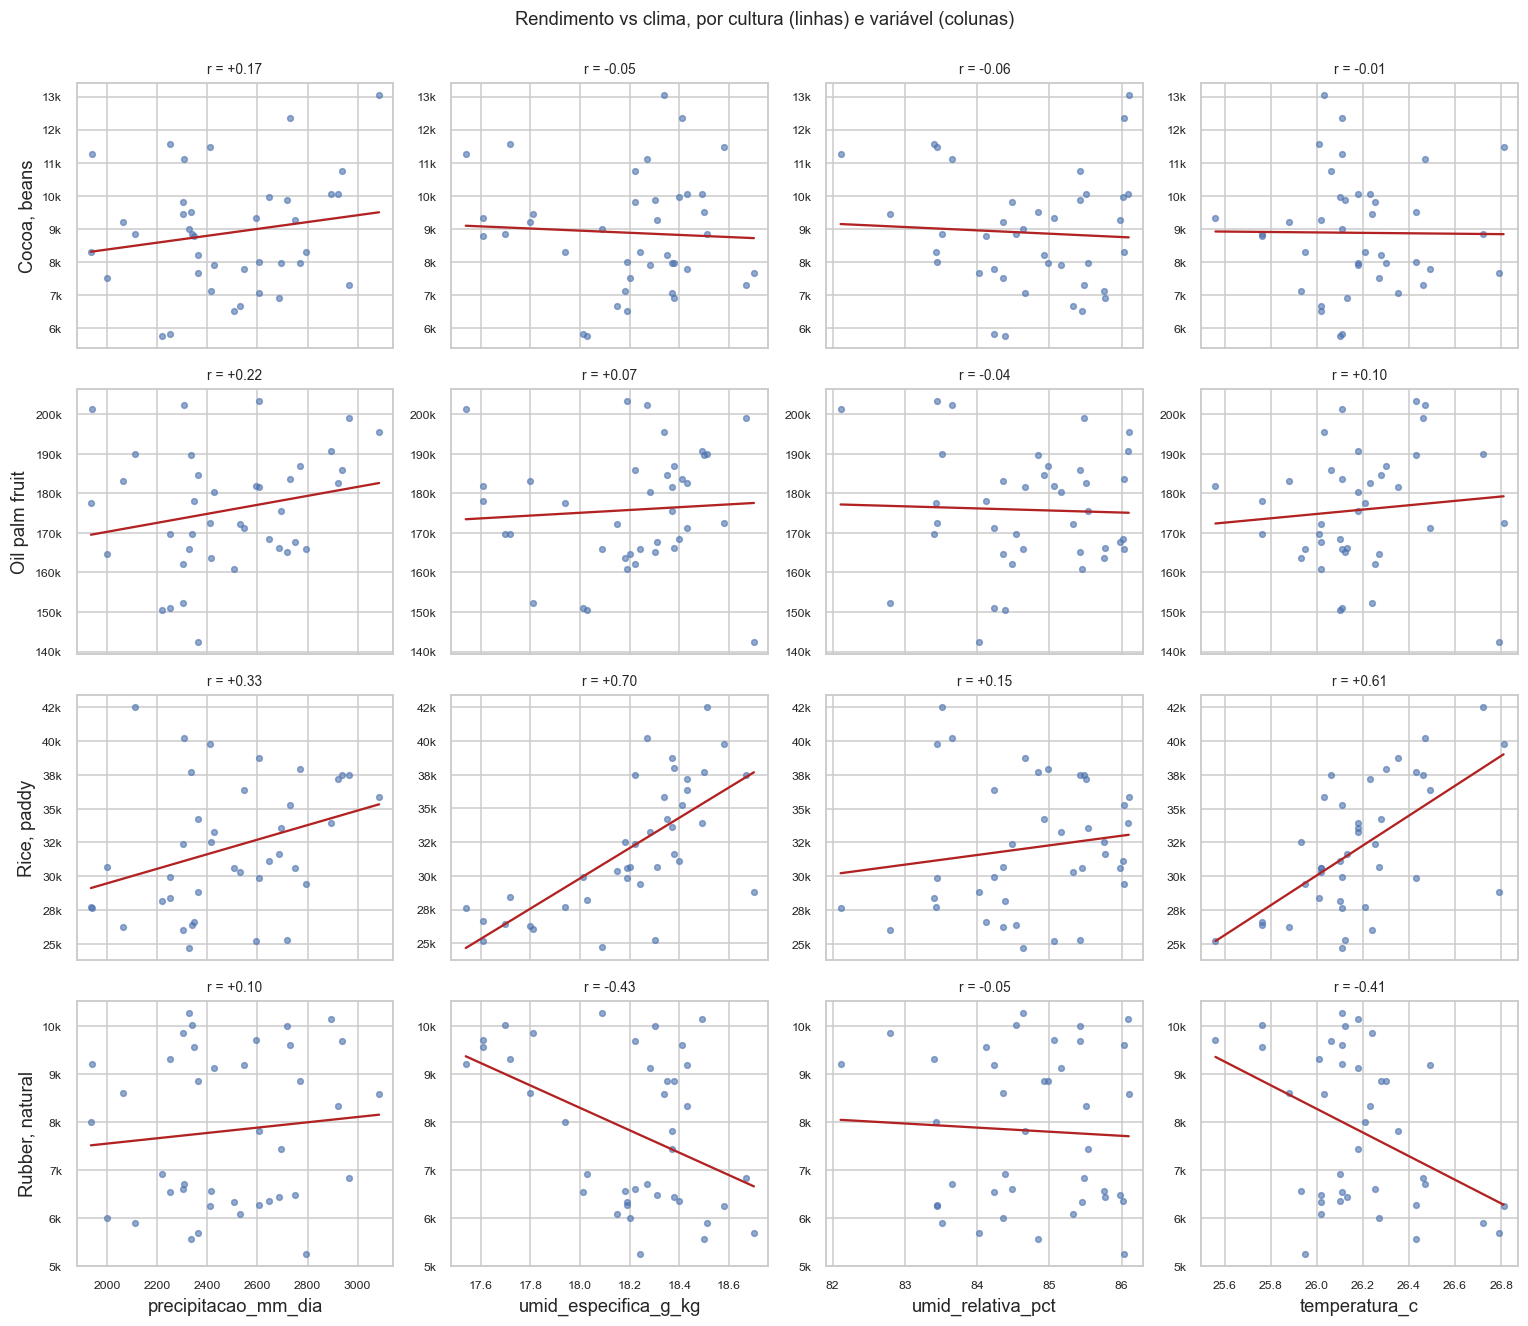

In [11]:
# Dispersão clima x rendimento por cultura, com ajuste linear.
# Um painel por combinação torna visível que o padrão não se repete entre culturas.
fig, axes = plt.subplots(4, 4, figsize=(14, 12), sharex='col')

for i, nome in enumerate(sorted(df['cultura'].unique())):
    g = df[df['cultura'] == nome]
    for j, col in enumerate(CLIMA):
        ax = axes[i, j]
        sns.regplot(data=g, x=col, y='rendimento', ax=ax,
                    scatter_kws={'s': 14, 'alpha': 0.6}, line_kws={'lw': 1.5, 'color': 'firebrick'},
                    ci=None)
        r = g[col].corr(g['rendimento'])
        ax.set_title(f'r = {r:+.2f}', fontsize=9)
        ax.set_xlabel(col if i == 3 else '')
        ax.set_ylabel(nome if j == 0 else '')
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f'{v/1000:.0f}k'))
        ax.tick_params(labelsize=8)

plt.suptitle('Rendimento vs clima, por cultura (linhas) e variável (colunas)', y=1.001, fontsize=12)
plt.tight_layout()
plt.show()

## 4. Teste da hipótese de correlação sensível à ordem do arquivo

O achado 4 deixou aberta uma pergunta: a correlação de +0.70 entre umidade específica e rendimento do arroz reflete uma associação estável com as variáveis climáticas ou é um artefato de duas sequências que variam juntas conforme a posição no arquivo?

O teste é exploratório. Removo de ambas as séries a componente linear em relação ao índice ordinal da linha e recalculo a correlação sobre os resíduos. Se a associação clima-rendimento for estável segundo esse critério, ela deve sobreviver. Se depender da ordenação do arquivo, deve colapsar.

Este teste não transforma o índice em tempo. Ele apenas verifica se a correlação depende de uma estrutura de ordenação que o dataset não explica.

In [12]:
def remover_componente_indice(serie, indice):
    """Remove a componente linear em relação ao índice ordinal da linha."""
    coef = np.polyfit(indice, serie, deg=1)
    return serie - np.polyval(coef, indice)


print('Correlação clima x rendimento: bruta vs após remover componente do índice\n')
print(f'{"Cultura":<18} {"Variável":<24} {"bruta":>8} {"residual":>10} {"queda":>8}')
print('-' * 72)

resultados_sem_indice = []
for nome, grupo in df.groupby('cultura'):
    g = grupo.sort_values('indice_registro').reset_index(drop=True)
    idx = g['indice_registro'].values.astype(float)
    resid_y = remover_componente_indice(g['rendimento'].values.astype(float), idx)
    for col in CLIMA:
        bruta = np.corrcoef(g[col], g['rendimento'])[0, 1]
        resid_x = remover_componente_indice(g[col].values.astype(float), idx)
        residual = np.corrcoef(resid_y, resid_x)[0, 1]
        resultados_sem_indice.append({'cultura': nome, 'variavel': col,
                                      'r_bruta': bruta, 'r_residual': residual})
        print(f'{nome:<18} {col:<24} {bruta:>+8.3f} {residual:>+10.3f} {abs(bruta)-abs(residual):>+8.3f}')
    print('-' * 72)

corr_sem_indice = pd.DataFrame(resultados_sem_indice)

Correlação clima x rendimento: bruta vs após remover componente do índice

Cultura            Variável                    bruta   residual    queda
------------------------------------------------------------------------
Cocoa, beans       precipitacao_mm_dia        +0.174     +0.145   +0.028
Cocoa, beans       umid_especifica_g_kg       -0.055     -0.229   -0.174
Cocoa, beans       umid_relativa_pct          -0.058     -0.083   -0.024
Cocoa, beans       temperatura_c              -0.010     -0.103   -0.093
------------------------------------------------------------------------
Oil palm fruit     precipitacao_mm_dia        +0.222     +0.017   +0.205
Oil palm fruit     umid_especifica_g_kg       +0.071     -0.634   -0.564
Oil palm fruit     umid_relativa_pct          -0.035     -0.170   -0.135
Oil palm fruit     temperatura_c              +0.097     -0.359   -0.262
------------------------------------------------------------------------
Rice, paddy        precipitacao_mm_dia        +0.

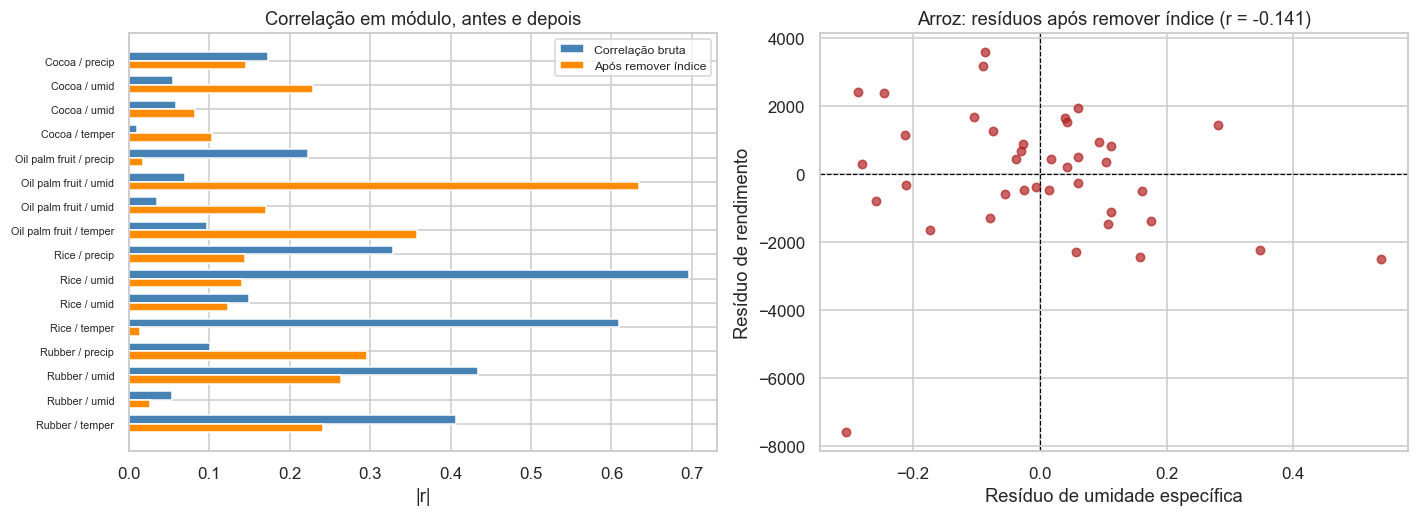

In [13]:
# Visualização do colapso da correlação após remover a componente associada ao índice
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

largura = 0.35
pos = np.arange(len(corr_sem_indice))
axes[0].barh(pos - largura/2, corr_sem_indice['r_bruta'].abs(), largura, label='Correlação bruta', color='steelblue')
axes[0].barh(pos + largura/2, corr_sem_indice['r_residual'].abs(), largura, label='Após remover índice', color='darkorange')
axes[0].set_yticks(pos)
axes[0].set_yticklabels([f"{r.cultura.split(',')[0]} / {r.variavel.split('_')[0][:6]}" for r in corr_sem_indice.itertuples()], fontsize=7)
axes[0].set_xlabel('|r|')
axes[0].set_title('Correlação em módulo, antes e depois')
axes[0].legend(fontsize=8)
axes[0].invert_yaxis()

# Caso mais forte: arroz e umidade específica
arroz = df[df['cultura'] == 'Rice, paddy'].sort_values('indice_registro').reset_index(drop=True)
idx = arroz['indice_registro'].values.astype(float)
rx = remover_componente_indice(arroz['umid_especifica_g_kg'].values.astype(float), idx)
ry = remover_componente_indice(arroz['rendimento'].values.astype(float), idx)
axes[1].scatter(rx, ry, s=30, alpha=0.7, color='firebrick')
axes[1].axhline(0, color='black', lw=0.8, ls='--')
axes[1].axvline(0, color='black', lw=0.8, ls='--')
axes[1].set_title(f'Arroz: resíduos após remover índice (r = {np.corrcoef(rx, ry)[0,1]:+.3f})')
axes[1].set_xlabel('Resíduo de umidade específica')
axes[1].set_ylabel('Resíduo de rendimento')

plt.tight_layout()
plt.show()

### Achado 5: o sinal climático mais forte é sensível à ordem do arquivo

Arroz e umidade específica: r cai de +0.697 para -0.141. Arroz e temperatura: de +0.609 para +0.013. Esses dois sinais brutos fortes praticamente desaparecem após remover a componente linear associada ao índice ordinal.

Esse colapso não ocorre em todos os pares. A execução atual mostra correlações residuais acima de 0.15 em módulo em dendê e umidade específica (-0.634), dendê e temperatura (-0.359), borracha e precipitação (+0.297), borracha e umidade específica (-0.264), borracha e temperatura (-0.242), cacau e umidade específica (-0.229) e dendê e umidade relativa (-0.170).

Como o dataset não informa data ou ano, isso não deve ser lido como remoção de tendência temporal. É um teste de robustez contra uma estrutura de ordenação que o arquivo não explica.

Na amostra disponível, essas correlações residuais não sustentam regra operacional. Elas indicam relações bivariadas heterogêneas que precisam ser confrontadas com a validação supervisionada agrupada.

**Consequência para a modelagem.** A partir daqui, o trabalho parte da hipótese de que as relações clima-rendimento são instáveis e que o clima nesta base não tem poder preditivo demonstrável sobre o rendimento. As seções 5 a 8 testam essa hipótese com cinco algoritmos, em vez de assumi-la.

## 5. Clusterização e descoberta de padrões

O enunciado pede identificar tendências de produtividade e cenários discrepantes. Executo duas clusterizações com objetivos distintos, porque uma só responderia à pergunta errada.

**Clusterização A**, sobre as 39 observações climáticas únicas: identifica regimes climáticos. Roda sobre os registros únicos porque replicar cada linha quatro vezes não adicionaria informação e apenas inflaria a densidade artificialmente.

**Clusterização B**, sobre clima mais rendimento normalizado dentro da cultura: testa se regimes climáticos correspondem a regimes de produtividade. A normalização intra-cultura é necessária. Sem ela, a escala de dendê, 22 vezes maior que a de borracha, domina a distância euclidiana e o algoritmo apenas reencontra a coluna `cultura`, o que não seria descoberta alguma.

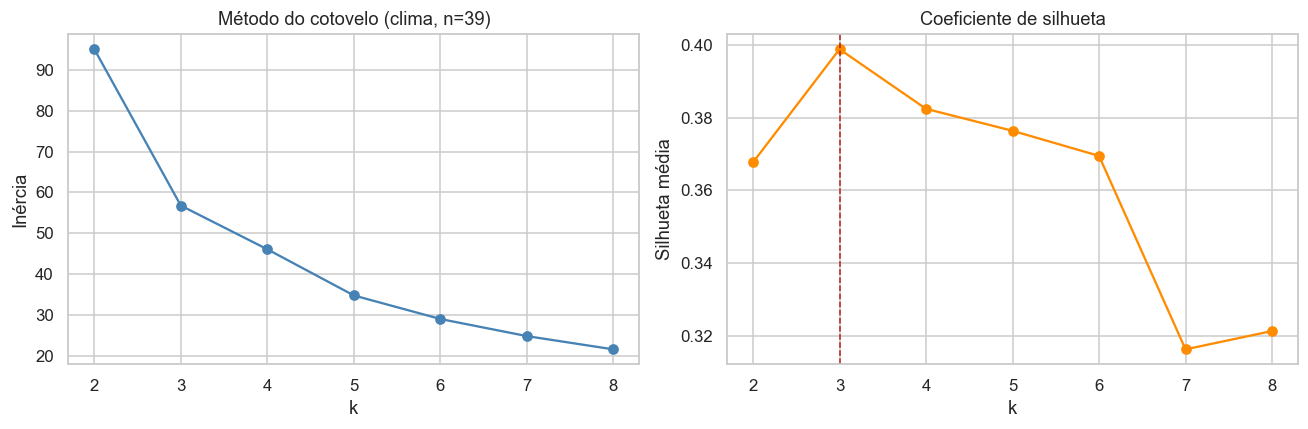

k com maior silhueta: 3 (silhueta = 0.399)

Interpretação: silhueta máxima de ~0.40 indica separação limitada.
A interpretação dos grupos deve permanecer exploratória.


In [14]:
# Escolha de k por dois critérios independentes: inércia (método do cotovelo)
# e silhueta. Não uso apenas o cotovelo porque sua leitura é subjetiva.
X_clima = StandardScaler().fit_transform(clima_ref[CLIMA])

ks = range(2, 9)
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=20).fit(X_clima)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_clima, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inercias, marker='o', color='steelblue')
axes[0].set_title('Método do cotovelo (clima, n=39)')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inércia')

axes[1].plot(list(ks), silhuetas, marker='o', color='darkorange')
axes[1].set_title('Coeficiente de silhueta')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhueta média')
melhor_k = list(ks)[int(np.argmax(silhuetas))]
axes[1].axvline(melhor_k, color='firebrick', ls='--', lw=1)
plt.tight_layout(); plt.show()

print(f'k com maior silhueta: {melhor_k} (silhueta = {max(silhuetas):.3f})')
print('\nInterpretação: silhueta máxima de ~0.40 indica separação limitada.')
print('A interpretação dos grupos deve permanecer exploratória.')

In [15]:
# Clusterização A: regimes climáticos sobre os 39 registros climáticos únicos
K_CLIMA = 3
km_clima = KMeans(n_clusters=K_CLIMA, random_state=SEED, n_init=20).fit(X_clima)
clima_ref = clima_ref.copy()
clima_ref['regime'] = km_clima.labels_

# Validação cruzada do resultado com um algoritmo de família diferente.
# Se hierárquico e KMeans concordam, a partição não é artefato de um método.
hier = AgglomerativeClustering(n_clusters=K_CLIMA, linkage='ward').fit(X_clima)
concordancia = pd.crosstab(km_clima.labels_, hier.labels_)
print('Concordância KMeans vs Agrupamento hierárquico:')
print(concordancia.to_string())
print(f'\nSilhueta hierárquico: {silhouette_score(X_clima, hier.labels_):.3f}')

perfil = clima_ref.groupby('regime')[CLIMA + ['indice_registro']].mean()
perfil['n'] = clima_ref['regime'].value_counts().sort_index()
print('\nPerfil médio de cada regime climático:')
display(perfil.round(2))

Concordância KMeans vs Agrupamento hierárquico:
col_0   0  1   2
row_0           
0       4  1  12
1       3  8   0
2      11  0   0

Silhueta hierárquico: 0.324

Perfil médio de cada regime climático:


,precipitacao_mm_dia,umid_especifica_g_kg,umid_relativa_pct,temperatura_c,indice_registro,n
regime,,,,,,
0,2733.52,18.34,85.65,26.12,21.53,17
1,2359.02,18.39,84.15,26.48,28.73,11
2,2232.22,17.81,83.92,25.99,5.36,11


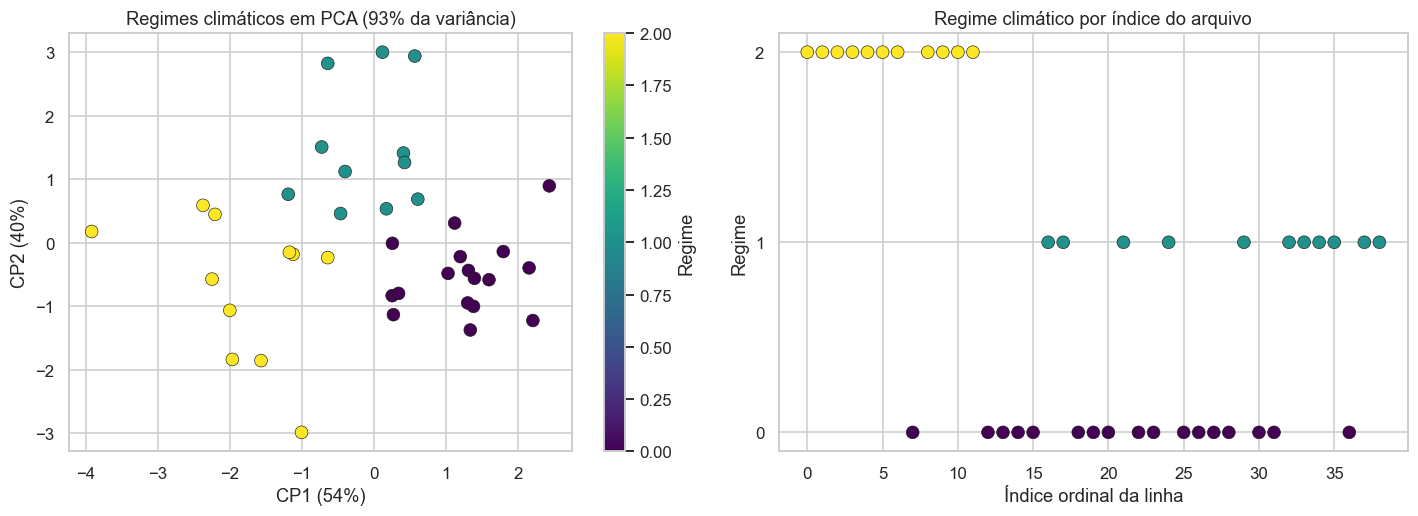

In [16]:
# Projeção PCA para visualizar os regimes em duas dimensões
pca = PCA(n_components=2, random_state=SEED)
proj = pca.fit_transform(X_clima)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sc = axes[0].scatter(proj[:, 0], proj[:, 1], c=clima_ref['regime'], cmap='viridis', s=70, edgecolor='k', lw=0.4)
axes[0].set_title(f'Regimes climáticos em PCA ({pca.explained_variance_ratio_.sum():.0%} da variância)')
axes[0].set_xlabel(f'CP1 ({pca.explained_variance_ratio_[0]:.0%})')
axes[0].set_ylabel(f'CP2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.colorbar(sc, ax=axes[0], label='Regime')

# O regime acompanha a posição no arquivo?
sc2 = axes[1].scatter(clima_ref['indice_registro'], clima_ref['regime'], c=clima_ref['regime'], cmap='viridis', s=70, edgecolor='k', lw=0.4)
axes[1].set_title('Regime climático por índice do arquivo')
axes[1].set_xlabel('Índice ordinal da linha'); axes[1].set_ylabel('Regime')
axes[1].set_yticks(range(K_CLIMA))
plt.tight_layout(); plt.show()

### Achado 6: os regimes climáticos acompanham a ordem do arquivo

Os clusters acompanham parcialmente a posição no arquivo, mas não formam faixas perfeitamente contíguas. O regime com índice médio 5,4 concentra os menores índices; os regimes com médias 21,5 e 28,7 ocupam posições médias e altas com sobreposição, e o de média 28,7 é o mais quente. O k-means, sem receber o índice como variável, reencontrou parte de um padrão associado à ordem do arquivo.

Isso é coerente como diagnóstico estrutural, mas não autoriza interpretação cronológica. Os clusters não podem ser chamados de eras, décadas ou períodos, porque o dataset não informa data nem ano.

A concordância entre k-means e agrupamento hierárquico é parcial. A diagonal da tabela cruzada não é dominante, e a silhueta do hierárquico (0.324) é inferior à do k-means (0.399). Duas famílias de algoritmo produzindo partições diferentes sobre os mesmos dados indica que a separação entre grupos é limitada e sensível ao método. Trato os regimes como interpretação exploratória, não como grupos reais comprovados.

In [17]:
# Clusterização B: os regimes climáticos correspondem a regimes de produtividade?
# Normalizo o rendimento dentro de cada cultura via z-score. Sem isso, a escala
# absoluta de dendê dominaria a distância e o cluster viraria sinônimo de cultura.
# Este rend_z global é descritivo/exploratório; a avaliação supervisionada do
# Experimento B calcula a normalização do alvo dentro de cada dobra.
df['rend_z'] = df.groupby('cultura')['rendimento'].transform(lambda s: (s - s.mean()) / s.std())

X_misto = StandardScaler().fit_transform(df[CLIMA + ['rend_z']])
km_misto = KMeans(n_clusters=3, random_state=SEED, n_init=20).fit(X_misto)
df['cluster_misto'] = km_misto.labels_

print('Distribuição dos clusters por cultura:')
tabela = pd.crosstab(df['cultura'], df['cluster_misto'])
display(tabela)

print('\nPerfil médio de cada cluster:')
display(df.groupby('cluster_misto')[CLIMA + ['rend_z', 'indice_registro']].mean().round(3))

print(f'\nSilhueta: {silhouette_score(X_misto, km_misto.labels_):.3f}')


Distribuição dos clusters por cultura:


cluster_misto,0,1,2
cultura,,,
"Cocoa, beans",17,11,11
Oil palm fruit,17,11,11
"Rice, paddy",17,11,11
"Rubber, natural",17,11,11



Perfil médio de cada cluster:


,precipitacao_mm_dia,umid_especifica_g_kg,umid_relativa_pct,temperatura_c,rend_z,indice_registro
cluster_misto,,,,,,
0,2733.518,18.338,85.652,26.119,0.078,21.529
1,2359.025,18.393,84.145,26.481,0.061,28.727
2,2232.217,17.805,83.916,25.986,-0.181,5.364



Silhueta: 0.329


### Achado 7: regimes climáticos não separam produtividade

A tabela cruzada mostra a mesma distribuição 17 / 11 / 11 nas quatro culturas. Na solução obtida, adicionar o rendimento padronizado por cultura não separou as culturas dentro dos mesmos cenários, e os clusters continuaram refletindo principalmente os perfis climáticos.

O perfil confirma: o `rend_z` médio dos três clusters fica em 0.08, 0.06 e -0.18. Uma amplitude de 0.26 desvio padrão entre o cluster mais e o menos produtivo. Não há separação relevante de produtividade neste teste.

Este teste não supervisionado complementa a seção 4: mesmo com algumas correlações residuais moderadas em pares específicos, a clusterização com rendimento normalizado não separa regimes de produtividade.

In [18]:
# Detecção de cenários discrepantes.
# Uso três critérios porque cada um captura um tipo diferente de anomalia,
# e reporto a concordância entre eles em vez de escolher um arbitrariamente.

# Critério 1: z-score do rendimento dentro da própria cultura (anomalia univariada)
df['out_zscore'] = df['rend_z'].abs() > 2.5

# Critério 2: IQR dentro da própria cultura (robusto a caudas)
def flag_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

df['out_iqr'] = df.groupby('cultura')['rendimento'].transform(flag_iqr)

# Critério 3: Isolation Forest no espaço multivariado clima + rendimento normalizado
iso = IsolationForest(contamination=0.05, random_state=SEED)
df['out_isolation'] = iso.fit_predict(X_misto) == -1

resumo_out = pd.DataFrame({
    'z-score intra-cultura (|z|>2.5)': [df['out_zscore'].sum()],
    'IQR intra-cultura': [df['out_iqr'].sum()],
    'Isolation Forest (5%)': [df['out_isolation'].sum()],
}, index=['registros sinalizados'])
display(resumo_out)

df['n_criterios'] = df[['out_zscore', 'out_iqr', 'out_isolation']].sum(axis=1)
suspeitos = df[df['n_criterios'] >= 1].sort_values('n_criterios', ascending=False)
print('\nRegistros sinalizados por ao menos um critério:')
display(suspeitos[['cultura', 'indice_registro', 'rendimento', 'rend_z',
                   'out_zscore', 'out_iqr', 'out_isolation', 'n_criterios']].round(3))

,z-score intra-cultura (|z|>2.5),IQR intra-cultura,Isolation Forest (5%)
registros sinalizados,0,0,8



Registros sinalizados por ao menos um critério:


,cultura,indice_registro,rendimento,rend_z,out_zscore,out_iqr,out_isolation,n_criterios
1,"Cocoa, beans",1,11253,1.358,False,False,True,1
27,"Cocoa, beans",27,13056,2.391,False,False,True,1
40,Oil palm fruit,1,201436,1.718,False,False,True,1
56,Oil palm fruit,17,142425,-2.237,False,False,True,1
79,"Rice, paddy",1,27619,-0.935,False,False,True,1
81,"Rice, paddy",3,25187,-1.443,False,False,True,1
116,"Rice, paddy",38,42550,2.182,False,False,True,1
118,"Rubber, natural",1,9223,0.874,False,False,True,1


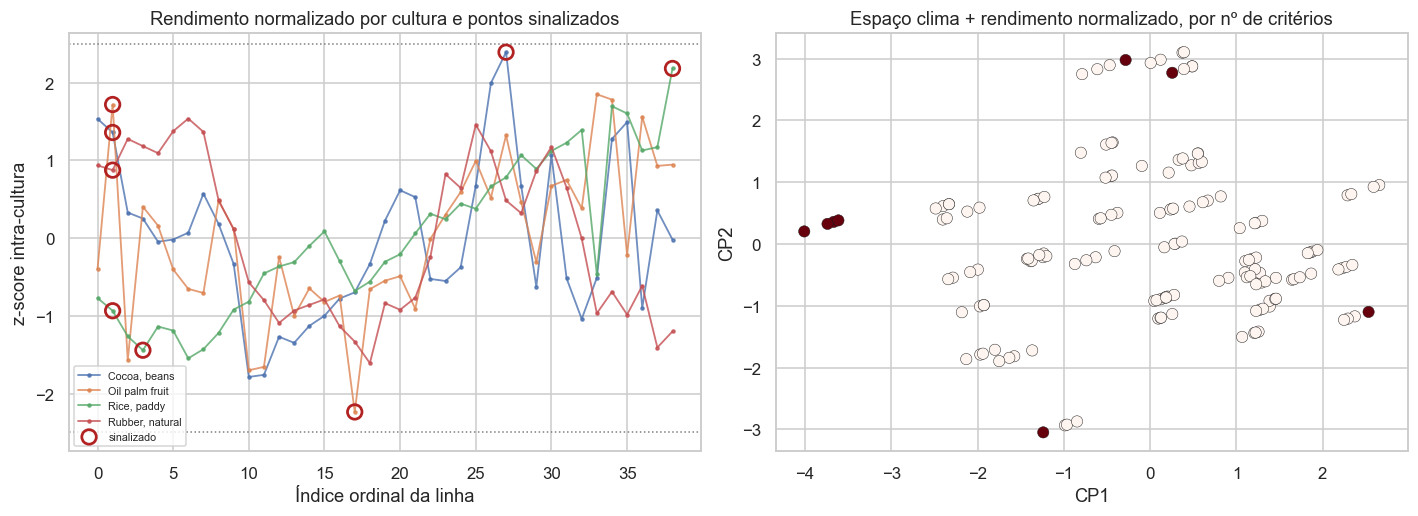

In [19]:
# Visualização dos pontos sinalizados
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for nome, grupo in df.groupby('cultura'):
    g = grupo.sort_values('indice_registro')
    axes[0].plot(g['indice_registro'], g['rend_z'], lw=1.2, marker='.', ms=4, label=nome, alpha=0.8)
marcados = df[df['n_criterios'] >= 1]
axes[0].scatter(marcados['indice_registro'], marcados['rend_z'], s=90, facecolors='none',
                edgecolors='firebrick', lw=1.8, label='sinalizado', zorder=5)
for lim in (-2.5, 2.5):
    axes[0].axhline(lim, color='gray', ls=':', lw=1)
axes[0].set_title('Rendimento normalizado por cultura e pontos sinalizados')
axes[0].set_xlabel('Índice ordinal da linha'); axes[0].set_ylabel('z-score intra-cultura')
axes[0].legend(fontsize=7)

proj_misto = PCA(n_components=2, random_state=SEED).fit_transform(X_misto)
axes[1].scatter(proj_misto[:, 0], proj_misto[:, 1], c=df['n_criterios'], cmap='Reds',
                s=55, edgecolor='k', lw=0.3)
axes[1].set_title('Espaço clima + rendimento normalizado, por nº de critérios')
axes[1].set_xlabel('CP1'); axes[1].set_ylabel('CP2')
plt.tight_layout(); plt.show()

### Achado 8: não foram identificados outliers robustos pelos critérios utilizados

Nenhum registro ultrapassa 2,5 desvios padrão dentro da própria cultura. O critério IQR também não sinaliza nada. Só o Isolation Forest marca registros, e ele marca por construção: o parâmetro `contamination=0.05` força a sinalização de aproximadamente 5% da base independentemente de haver anomalia real. Os pontos que ele marca ficam entre 0.87 e 2.39 desvios padrão, o que não fornece evidência consensual de outlier pelos critérios utilizados.

A conclusão limitada aos métodos aplicados é que não foram identificados outliers robustos ou consensuais nas quatro séries.

A diferença de patamar entre culturas é estrutural: dendê opera em um patamar 22 vezes superior ao de borracha. Essa diferença não é tratada como outlier; é característica da cultura, e é exatamente o que os modelos da próxima seção capturam em grande parte.

Nota metodológica: a ausência de outliers robustos pelos critérios utilizados é informação sobre a base, mas não prova que anomalias moderadas inexistam.

## 6. Desenho experimental da modelagem

O enunciado pede cinco modelos preditivos com algoritmos diferentes. A escolha dos algoritmos importa menos do que a escolha do que comparar contra o quê. Um R² de 0.99 só significa alguma coisa se houver um referencial.

### Baseline

Adoto como baseline do experimento A o preditor que devolve a média observada de rendimento da própria cultura, ignorando completamente o clima. É o modelo mais simples que um agrônomo usaria sem nenhuma análise de dados. Se os cinco algoritmos não o superarem de forma material, o clima não demonstrou contribuição preditiva útil neste dataset.

Reporto também a média global como referência de piso.

No experimento B, o baseline correto é prever `z = 0`: isto é, prever que a observação ficará exatamente no padrão da cultura aprendido apenas no treino da dobra. Como a normalização agora é aprendida dentro da dobra, R² e RMSE desse baseline são medidos empiricamente no teste.

### Dois experimentos

**Experimento A** prevê o rendimento absoluto a partir de clima mais a cultura codificada. Responde: quanto rende esta cultura sob estas condições? É o enunciado literal, e é onde os R² altos vão aparecer.

**Experimento B** prevê o rendimento normalizado dentro da cultura a partir do clima apenas. Responde: dado que já sei a cultura, o clima ajuda a prever se este registro fica acima ou abaixo da média dela? É a pergunta que tem valor de decisão para a fazenda, e o experimento A não a responde.

### Validação

A avaliação principal usa `GroupKFold(n_splits=5)` com `cenario_climatico` como grupo. Assim, as quatro linhas do mesmo cenário climático ficam sempre juntas no treino ou no teste. O identificador de grupo é usado apenas para montar as dobras; ele não entra em `X_A`, `X_B` nem em qualquer função de previsão.

Em todas as dobras, o notebook verifica programaticamente que `cenários_treino ∩ cenários_teste = ∅`.

No experimento B, a coluna global `rend_z` continua existindo apenas como estatística descritiva das análises exploratórias. Ela não é usada como alvo supervisionado. Em cada dobra, média e desvio-padrão por cultura são calculados no treino e aplicados tanto ao alvo de treino quanto ao alvo de teste daquela dobra.

### Métricas

RMSE em unidade do alvo, MAE por ser robusto a caudas, R² para comparabilidade entre experimentos de escalas diferentes, e MAPE para leitura de negócio. RMSE isolado seria insuficiente porque a escala varia 22 vezes entre culturas.

### Algoritmos

Cinco famílias distintas, escolhidas para cobrir premissas diferentes: linear paramétrica, particionamento único, bagging, boosting, e kernel. Uso hiperparâmetros conservadores e fixos. Com 39 cenários climáticos distintos, uma busca extensa de hiperparâmetros aumentaria o risco de ajuste excessivo ao protocolo de validação.


### 6.1. Os cinco modelos preditivos

O enunciado exige cinco modelos, cada um com um algoritmo diferente. A escolha não foi por conveniência de biblioteca. Cada algoritmo carrega uma premissa distinta sobre a forma da relação entre preditores e alvo, e a comparação só é informativa se as premissas forem realmente diferentes entre si.

| # | Modelo | Classe scikit-learn | Família | Premissa sobre a relação preditor-alvo |
|---|---|---|---|---|
| 1 | Regressão linear | `LinearRegression` | Linear paramétrica | Aditiva e linear, sem interações |
| 2 | Árvore de decisão | `DecisionTreeRegressor` | Particionamento único | Constante por partes, fronteiras ortogonais aos eixos |
| 3 | Random forest | `RandomForestRegressor` | Ensemble por bagging | Média de árvores decorrelacionadas |
| 4 | Gradient boosting | `GradientBoostingRegressor` | Ensemble por boosting | Soma sequencial de árvores rasas ajustadas aos resíduos |
| 5 | SVR com kernel RBF | `SVR` + `TransformedTargetRegressor` | Kernel | Similaridade local em espaço de dimensão elevada |

---

#### Modelo 1: Regressão linear

`LinearRegression()`, sem regularização.

Serve como referência interpretável. Se o modelo linear apresenta desempenho semelhante aos ensembles, isso sugere que a flexibilidade adicional desses modelos não trouxe ganho relevante neste protocolo. Não uso Ridge ou Lasso porque o objetivo aqui é o coeficiente sem encolhimento, para leitura direta.

Limitação conhecida neste dataset: precipitação e umidade relativa correlacionam a 0.75, e umidade específica e temperatura a 0.70. Essa multicolinearidade desestabiliza os coeficientes individuais, embora não prejudique a predição agregada. Por isso não interpreto coeficientes isolados, e uso permutation importance na seção 8.

#### Modelo 2: Árvore de decisão

`DecisionTreeRegressor(max_depth=5, min_samples_leaf=3, random_state=42)`.

`max_depth=5` e `min_samples_leaf=3` são restrições deliberadas. Uma árvore sem poda em 156 linhas memoriza a base inteira e produz R² de treino igual a 1. As duas restrições reduzem o risco de ajuste perfeito e tornam o gap treino-teste interpretável.

É o único modelo do conjunto que não é ensemble, o que permite observar sinais de sobreajuste em um particionador simples nesta base.

#### Modelo 3: Random forest

`RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)`.

300 árvores é uma escolha conservadora para estabilizar a média em uma base deste tamanho; acima disso o custo cresce linearmente. `min_samples_leaf=2` limita folhas com uma observação só, situação plausível em uma base com poucos cenários climáticos distintos.

O bagging da Random Forest tende a reduzir variância em relação a uma única árvore, permitindo comparar essa estratégia com as demais famílias de modelos.

#### Modelo 4: Gradient boosting

`GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)`.

`learning_rate=0.05` com `n_estimators=200` é a combinação conservadora padrão: passo pequeno compensado por mais iterações. `max_depth=3` mantém as árvores rasas, que é a premissa do boosting, aprendizes fracos somados sequencialmente.

O boosting combina árvores sequenciais para corrigir erros residuais, oferecendo uma estratégia de ensemble diferente da Random Forest.

#### Modelo 5: SVR com kernel RBF

`TransformedTargetRegressor(regressor=SVR(C=10, gamma='scale', epsilon=0.05), transformer=StandardScaler())`.

Único modelo que exige tratamento especial. O SVR é sensível à escala do alvo, e o rendimento varia de 5.249 a 203.399. O alvo foi padronizado para reduzir essa sensibilidade à escala e tornar a comparação entre algoritmos mais estável. O `TransformedTargetRegressor` padroniza o alvo no treino e desfaz a transformação na predição.

`C=10` é uma regularização moderada. `epsilon=0.05` opera sobre o alvo já padronizado.

Registro antecipado: o SVR apresentou desempenho inferior empiricamente neste dataset e com os hiperparâmetros fixados. O kernel RBF modela relações por similaridade no espaço transformado de features; no experimento A, `cultura` faz parte desse espaço e diferencia observações que compartilham o mesmo clima. Portanto, não atribuo o desempenho ruim simplesmente ao fato de haver clima igual para culturas diferentes. A combinação entre poucos cenários climáticos, forte estrutura categórica por cultura, relações potencialmente complexas e hiperparâmetros fixos pode contribuir para esse resultado.

---

#### Decisão sobre hiperparâmetros

Nenhum modelo passou por `GridSearchCV` ou `RandomizedSearchCV`. Com apenas 39 cenários climáticos distintos, uma busca extensa aumentaria o risco de selecionar configurações ajustadas ao protocolo de validação.

Os valores acima são conservadores e fixos; não houve busca automática de hiperparâmetros. Essa decisão é discutida como limitação na seção 11.

In [20]:
def construir_modelos():
    """Devolve os cinco algoritmos exigidos, cada um de uma família distinta.

    SVR recebe TransformedTargetRegressor para reduzir a sensibilidade à escala
    do alvo e tornar a comparação mais estável.
    """
    return {
        'Regressão linear': LinearRegression(),
        'Árvore de decisão': DecisionTreeRegressor(max_depth=5, min_samples_leaf=3, random_state=SEED),
        'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
        'Gradient boosting': GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED),
        'SVR (RBF)': TransformedTargetRegressor(regressor=SVR(C=10, gamma='scale', epsilon=0.05), transformer=StandardScaler()),
    }


def mape(y_true, y_pred):
    """Erro percentual absoluto médio. Só é interpretável com alvo estritamente positivo."""
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


CV = GroupKFold(n_splits=5)
GROUPS = df['cenario_climatico']
SCORING = {'r2': 'r2', 'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'}

resumo_dobras = []
for dobra, (tr, te) in enumerate(CV.split(df, groups=GROUPS), start=1):
    cenarios_treino = set(GROUPS.iloc[tr])
    cenarios_teste = set(GROUPS.iloc[te])
    intersecao = cenarios_treino & cenarios_teste
    resumo_dobras.append({
        'dobra': dobra,
        'linhas_treino': len(tr),
        'linhas_teste': len(te),
        'cenários_treino': len(cenarios_treino),
        'cenários_teste': len(cenarios_teste),
        'interseção treino-teste': len(intersecao),
    })
    assert len(intersecao) == 0

resumo_dobras = pd.DataFrame(resumo_dobras)
print('Validação agrupada configurada: GroupKFold(n_splits=5)')
print('Checagem explícita: cenários_treino ∩ cenários_teste = ∅ em todas as dobras')
display(resumo_dobras)

print('Algoritmos configurados:')
for nome in construir_modelos():
    print(' -', nome)

Validação agrupada configurada: GroupKFold(n_splits=5)
Checagem explícita: cenários_treino ∩ cenários_teste = ∅ em todas as dobras


,dobra,linhas_treino,linhas_teste,cenários_treino,cenários_teste,interseção treino-teste
0,1,124,32,31,8,0
1,2,124,32,31,8,0
2,3,124,32,31,8,0
3,4,124,32,31,8,0
4,5,128,28,32,7,0


Algoritmos configurados:
 - Regressão linear
 - Árvore de decisão
 - Random forest
 - Gradient boosting
 - SVR (RBF)


In [21]:
# Inventário explícito dos cinco modelos, com hiperparâmetros efetivos.
# Esta célula existe para tornar auditável exatamente o que foi treinado.

FAMILIAS = {
    'Regressão linear':  'Linear paramétrica',
    'Árvore de decisão': 'Particionamento único',
    'Random forest':     'Ensemble por bagging',
    'Gradient boosting': 'Ensemble por boosting',
    'SVR (RBF)':         'Kernel',
}

print('=' * 78)
print('INVENTÁRIO DOS CINCO MODELOS PREDITIVOS'.center(78))
print('=' * 78)

for i, (nome, modelo) in enumerate(construir_modelos().items(), start=1):
    # TransformedTargetRegressor encapsula o estimador real; extraio o interno
    interno = getattr(modelo, 'regressor', modelo)
    print(f'\n[{i}] {nome}')
    print(f'    Família        : {FAMILIAS[nome]}')
    print(f'    Classe         : {type(interno).__name__}')
    if interno is not modelo:
        print(f'    Encapsulamento : {type(modelo).__name__} com StandardScaler no alvo')
    # Mostro apenas os hiperparâmetros que difere do padrão da biblioteca
    padrao = type(interno)()
    ajustados = {k: v for k, v in interno.get_params().items()
                 if padrao.get_params().get(k) != v}
    if ajustados:
        print('    Hiperparâmetros ajustados:')
        for k, v in sorted(ajustados.items()):
            print(f'        {k} = {v}')
    else:
        print('    Hiperparâmetros: todos no padrão da biblioteca')

print('\n' + '=' * 78)
print(f'Total de modelos: {len(construir_modelos())} | Famílias distintas: {len(set(FAMILIAS.values()))}')
print('Todos avaliados sobre as mesmas dobras agrupadas por cenário climático.')
print('=' * 78)

                   INVENTÁRIO DOS CINCO MODELOS PREDITIVOS                    

[1] Regressão linear
    Família        : Linear paramétrica
    Classe         : LinearRegression
    Hiperparâmetros: todos no padrão da biblioteca

[2] Árvore de decisão
    Família        : Particionamento único
    Classe         : DecisionTreeRegressor
    Hiperparâmetros ajustados:
        max_depth = 5
        min_samples_leaf = 3
        random_state = 42

[3] Random forest
    Família        : Ensemble por bagging
    Classe         : RandomForestRegressor
    Hiperparâmetros ajustados:
        min_samples_leaf = 2
        n_estimators = 300
        n_jobs = -1
        random_state = 42

[4] Gradient boosting
    Família        : Ensemble por boosting
    Classe         : GradientBoostingRegressor
    Hiperparâmetros ajustados:
        learning_rate = 0.05
        n_estimators = 200
        random_state = 42

[5] SVR (RBF)
    Família        : Kernel
    Classe         : SVR
    Encapsulamento : T

In [22]:
# EXPERIMENTO A: clima + cultura -> rendimento absoluto

# Pré-processador. Padronizo o clima e aplico one-hot na cultura com drop='first'
# para evitar colinearidade perfeita na regressão linear.
pre_A = ColumnTransformer([
    ('num', StandardScaler(), CLIMA),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), ['cultura']),
])

X_A = df[CLIMA + ['cultura']]
y_A = df[ALVO]

linhas = []

# Baseline 1: média global, calculada apenas com o treino de cada dobra
r2s, rmses, maes, mapes = [], [], [], []
for tr, te in CV.split(X_A, y_A, groups=GROUPS):
    pred = np.full(len(te), y_A.iloc[tr].mean())
    yt = y_A.iloc[te]
    r2s.append(r2_score(yt, pred)); rmses.append(root_mean_squared_error(yt, pred))
    maes.append(mean_absolute_error(yt, pred)); mapes.append(mape(yt, pred))
linhas.append({'modelo': 'Baseline: média global', 'r2': np.mean(r2s), 'rmse': np.mean(rmses),
               'mae': np.mean(maes), 'mape': np.mean(mapes), 'r2_dp': np.std(r2s)})

# Baseline 2: média da própria cultura, calculada apenas com o treino de cada dobra
r2s, rmses, maes, mapes = [], [], [], []
for tr, te in CV.split(X_A, y_A, groups=GROUPS):
    medias = df.iloc[tr].groupby('cultura')[ALVO].mean()
    pred = df.iloc[te]['cultura'].map(medias).fillna(y_A.iloc[tr].mean()).values
    yt = y_A.iloc[te]
    r2s.append(r2_score(yt, pred)); rmses.append(root_mean_squared_error(yt, pred))
    maes.append(mean_absolute_error(yt, pred)); mapes.append(mape(yt, pred))
linhas.append({'modelo': 'Baseline: média da cultura', 'r2': np.mean(r2s), 'rmse': np.mean(rmses),
               'mae': np.mean(maes), 'mape': np.mean(mapes), 'r2_dp': np.std(r2s)})

# Os cinco algoritmos
for nome, modelo in construir_modelos().items():
    pipe = Pipeline([('pre', pre_A), ('modelo', modelo)])
    cvres = cross_validate(pipe, X_A, y_A, cv=CV, groups=GROUPS,
                           scoring=SCORING, return_train_score=True)
    # MAPE exige loop manual porque não está entre os scorers padrão
    mp = []
    for tr, te in CV.split(X_A, y_A, groups=GROUPS):
        p = Pipeline([('pre', pre_A), ('modelo', modelo)]).fit(X_A.iloc[tr], y_A.iloc[tr])
        mp.append(mape(y_A.iloc[te], p.predict(X_A.iloc[te])))
    linhas.append({'modelo': nome, 'r2': cvres['test_r2'].mean(), 'rmse': -cvres['test_rmse'].mean(),
                   'mae': -cvres['test_mae'].mean(), 'mape': np.mean(mp),
                   'r2_dp': cvres['test_r2'].std(), 'r2_treino': cvres['train_r2'].mean()})

res_A = pd.DataFrame(linhas).set_index('modelo')
res_A['ganho_vs_baseline_rmse'] = (res_A.loc['Baseline: média da cultura', 'rmse'] - res_A['rmse']) / res_A.loc['Baseline: média da cultura', 'rmse'] * 100
print('EXPERIMENTO A: clima + cultura -> rendimento absoluto | GroupKFold(5) por cenário climático\n')
display(res_A.round(3))

EXPERIMENTO A: clima + cultura -> rendimento absoluto | GroupKFold(5) por cenário climático



,r2,rmse,mae,mape,r2_dp,r2_treino,ganho_vs_baseline_rmse
modelo,,,,,,,
Baseline: média global,-0.000,70201.742,59840.184,337.720,0.000,NaN,-795.436
Baseline: média da cultura,0.987,7839.948,4828.496,13.959,0.004,NaN,0.000
Regressão linear,0.987,7873.869,5090.785,18.405,0.005,0.989,-0.433
Árvore de decisão,0.985,8649.646,4742.825,12.187,0.004,0.995,-10.328
Random forest,0.988,7418.108,4113.705,11.124,0.005,0.997,5.381
Gradient boosting,0.987,7943.422,4534.434,12.121,0.006,0.999,-1.320
SVR (RBF),0.959,13336.754,9574.270,59.004,0.031,0.998,-70.113


### Achado 9: os cinco modelos continuam próximos do baseline

Com validação agrupada por cenário climático, a comparação deixa de permitir que o mesmo cenário apareça no treino sob uma cultura e no teste sob outra. Essa é a avaliação principal do notebook a partir daqui.

O baseline da média da cultura segue sendo o referencial substantivo. Se um algoritmo não supera esse baseline de forma material, ele não demonstrou que as variáveis climáticas acrescentam capacidade preditiva útil além da identidade da cultura.

O que a tabela mostra: o R² alto continua medindo principalmente a capacidade de saber que dendê rende mais que borracha. Ele não mede, por si só, capacidade de explicar a variação de rendimento dentro de cada cultura. As quatro variáveis climáticas precisam ser lidas contra o ganho incremental sobre o baseline.

O SVR fica abaixo dos demais mesmo com padronização do alvo. O kernel RBF modela relações por similaridade no espaço transformado de features; no experimento A, `cultura` também faz parte desse espaço e diferencia observações com o mesmo vetor climático. Assim, o desempenho inferior é uma constatação empírica deste dataset com hiperparâmetros fixos, possivelmente associada à combinação entre poucos cenários climáticos, forte estrutura categórica por cultura e relações complexas.

#### Leitura individual de cada modelo no experimento A

Valores de validação cruzada agrupada por cenário climático, 5 dobras. A tabela numérica da célula anterior é a fonte auditável dos R², RMSE, MAE e MAPE.

Três leituras que a tabela agregada esconderia.

**Os quatro primeiros convergem apesar de premissas diferentes.** Um modelo linear, um particionador, um bagging e um boosting chegam à mesma faixa de desempenho. Isso sugere que a flexibilidade adicional desses modelos não trouxe ganho relevante neste protocolo.

**O R² de treino é o alerta.** Todos os cinco têm capacidade alta no conjunto de treino. Se o ganho no teste agrupado é pequeno, o gap treino-teste indica que parte da estrutura aprendida no conjunto de treino não se mantém nos cenários climáticos deixados fora da dobra.

**O SVR é a exceção empírica.** Ele apresentou desempenho inferior neste dataset e com os hiperparâmetros fixados. Como o kernel RBF usa similaridade no espaço transformado de features, não é correto atribuir o resultado simplesmente ao clima repetido entre culturas: no experimento A, `cultura` entra como feature e diferencia essas observações. A leitura mais cautelosa é que poucos cenários climáticos, forte estrutura categórica por cultura, relações potencialmente complexas e hiperparâmetros fixos podem ter contribuído para o desempenho observado.

In [23]:
# EXPERIMENTO B: clima -> rendimento normalizado dentro da cultura
# A cultura é removida das features. Ela só seleciona a média e o desvio-padrão
# do rendimento calculados no treino de cada dobra.

X_B = df[CLIMA]
assert list(X_B.columns) == CLIMA
assert 'cultura' not in X_B.columns
assert 'rend_z' not in X_B.columns

PREDITORES_B = ['Baseline: z = 0'] + list(construir_modelos().keys())
oof_B = df[['cenario_climatico', 'cultura', ALVO]].rename(columns={ALVO: 'real'}).copy()
oof_B['dobra'] = np.nan
oof_B['real_z'] = np.nan
for col in PREDITORES_B:
    oof_B[col] = np.nan

contador_oof_B = pd.Series(0, index=df.index, dtype=int)
metricas_B_dobras = {nome: [] for nome in PREDITORES_B}
linhas_dobras_B = []
estatisticas_teste_B = []
culturas_esperadas = set(culturas)


def normalizar_alvo_na_dobra(posicoes, stats_cultura):
    bloco = df.iloc[posicoes]
    medias = bloco['cultura'].map(stats_cultura['media_treino']).astype(float)
    desvios = bloco['cultura'].map(stats_cultura['desvio_treino']).astype(float)
    z = ((bloco[ALVO] - medias) / desvios).astype(float)
    return z, medias, desvios


for dobra, (tr, te) in enumerate(CV.split(X_B, groups=GROUPS), start=1):
    treino = df.iloc[tr]
    teste = df.iloc[te]

    cenarios_treino = set(treino['cenario_climatico'])
    cenarios_teste = set(teste['cenario_climatico'])
    intersecao = cenarios_treino & cenarios_teste
    assert len(intersecao) == 0

    stats = treino.groupby('cultura')[ALVO].agg(
        media_treino='mean',
        desvio_treino='std',
        n_treino='size',
    )
    culturas_presentes = set(stats.index)
    stats_validas = (
        culturas_presentes == culturas_esperadas
        and stats['media_treino'].notna().all()
        and stats['desvio_treino'].notna().all()
        and np.isfinite(stats['desvio_treino']).all()
        and stats['desvio_treino'].gt(0).all()
    )
    assert stats_validas

    y_train_z, _, _ = normalizar_alvo_na_dobra(tr, stats)
    y_test_z, media_teste, desvio_teste = normalizar_alvo_na_dobra(te, stats)
    assert y_train_z.notna().all()
    assert y_test_z.notna().all()
    assert np.isfinite(y_train_z).all()
    assert np.isfinite(y_test_z).all()

    idx_teste = teste.index
    contador_oof_B.loc[idx_teste] = contador_oof_B.loc[idx_teste] + 1
    oof_B.loc[idx_teste, 'dobra'] = dobra
    oof_B.loc[idx_teste, 'real_z'] = y_test_z.values
    oof_B.loc[idx_teste, 'Baseline: z = 0'] = 0.0

    pred_zero_train = np.zeros(len(tr))
    pred_zero_test = np.zeros(len(te))
    metricas_B_dobras['Baseline: z = 0'].append({
        'dobra': dobra,
        'r2_teste': r2_score(y_test_z, pred_zero_test),
        'r2_treino': r2_score(y_train_z, pred_zero_train),
        'rmse': root_mean_squared_error(y_test_z, pred_zero_test),
        'mae': mean_absolute_error(y_test_z, pred_zero_test),
    })

    estatisticas_teste_B.append(pd.DataFrame({
        'dobra': dobra,
        'cenario_climatico': teste['cenario_climatico'].values,
        'cultura': teste['cultura'].values,
        'rendimento': teste[ALVO].values,
        'media_treino_cultura': media_teste.values,
        'desvio_treino_cultura': desvio_teste.values,
        'n_treino_cultura': teste['cultura'].map(stats['n_treino']).values,
        'linha_usada_no_calculo': teste.index.isin(treino.index),
        'z_teste': y_test_z.values,
    }, index=idx_teste))

    for nome, modelo in construir_modelos().items():
        pipe = Pipeline([('scaler', StandardScaler()), ('modelo', modelo)])
        pipe.fit(X_B.iloc[tr], y_train_z)

        pred_train = np.asarray(pipe.predict(X_B.iloc[tr]), dtype=float)
        pred_test = np.asarray(pipe.predict(X_B.iloc[te]), dtype=float)
        assert np.isfinite(pred_train).all()
        assert np.isfinite(pred_test).all()

        oof_B.loc[idx_teste, nome] = pred_test
        metricas_B_dobras[nome].append({
            'dobra': dobra,
            'r2_teste': r2_score(y_test_z, pred_test),
            'r2_treino': r2_score(y_train_z, pred_train),
            'rmse': root_mean_squared_error(y_test_z, pred_test),
            'mae': mean_absolute_error(y_test_z, pred_test),
        })

    linhas_dobras_B.append({
        'dobra': dobra,
        'linhas_treino': len(tr),
        'linhas_teste': len(te),
        'cenários_treino': len(cenarios_treino),
        'cenários_teste': len(cenarios_teste),
        'interseção treino-teste': len(intersecao),
        'culturas_treino': len(culturas_presentes),
        'menor_n_cultura_treino': int(stats['n_treino'].min()),
        'menor_desvio_treino': float(stats['desvio_treino'].min()),
        'estatisticas_validas': bool(stats_validas),
    })

verificacao_B = pd.DataFrame(linhas_dobras_B)
estatisticas_teste_B = pd.concat(estatisticas_teste_B).sort_index()

assert contador_oof_B.eq(1).all()
assert oof_B['dobra'].notna().all()
assert not oof_B[['real_z'] + PREDITORES_B].isna().any().any()
assert np.isfinite(oof_B[['real_z'] + PREDITORES_B].to_numpy()).all()
assert not estatisticas_teste_B[['media_treino_cultura', 'desvio_treino_cultura', 'z_teste']].isna().any().any()
assert not estatisticas_teste_B['linha_usada_no_calculo'].any()

linhas_B = []
for nome, metricas in metricas_B_dobras.items():
    dob = pd.DataFrame(metricas)
    linhas_B.append({
        'modelo': nome,
        'r2_teste': dob['r2_teste'].mean(),
        'r2_treino': dob['r2_treino'].mean(),
        'r2_dp': dob['r2_teste'].std(ddof=0),
        'rmse': dob['rmse'].mean(),
        'mae': dob['mae'].mean(),
    })

res_B = pd.DataFrame(linhas_B).set_index('modelo')
res_B['ganho_vs_baseline_rmse'] = (
    (res_B.loc['Baseline: z = 0', 'rmse'] - res_B['rmse'])
    / res_B.loc['Baseline: z = 0', 'rmse'] * 100
)

metricas_B_por_dobra = pd.concat(
    [pd.DataFrame(metricas).assign(modelo=nome) for nome, metricas in metricas_B_dobras.items()],
    ignore_index=True,
)

res_B_oof = pd.DataFrame([{
    'modelo': nome,
    'r2': r2_score(oof_B['real_z'], oof_B[nome]),
    'rmse': root_mean_squared_error(oof_B['real_z'], oof_B[nome]),
    'mae': mean_absolute_error(oof_B['real_z'], oof_B[nome]),
} for nome in PREDITORES_B]).set_index('modelo')
res_B_oof['ganho_vs_baseline_rmse'] = (
    (res_B_oof.loc['Baseline: z = 0', 'rmse'] - res_B_oof['rmse'])
    / res_B_oof.loc['Baseline: z = 0', 'rmse'] * 100
)

verificacoes_p003 = pd.DataFrame({
    'valor': [
        bool((verificacao_B['interseção treino-teste'] == 0).all()),
        bool(verificacao_B['estatisticas_validas'].all()),
        bool(contador_oof_B.eq(1).all()),
        int(contador_oof_B.sum()),
        bool(not oof_B[['real_z'] + PREDITORES_B].isna().any().any()),
        bool(np.isfinite(oof_B[['real_z'] + PREDITORES_B].to_numpy()).all()),
        bool(not estatisticas_teste_B['linha_usada_no_calculo'].any()),
        list(X_B.columns),
    ]
}, index=[
    'sem cenário compartilhado nas dobras',
    'estatísticas por cultura válidas em todas as dobras',
    'cada observação recebeu exatamente uma previsão OOF B',
    'total de previsões OOF B',
    'sem NaN em normalizações/previsões B',
    'valores finitos em normalizações/previsões B',
    'linhas de teste fora do cálculo de média/desvio',
    'features do Experimento B',
])

print('EXPERIMENTO B: clima -> rendimento normalizado dentro da cultura | GroupKFold(5) por cenário climático')
print('Normalização do alvo: média e desvio-padrão por cultura calculados somente no treino de cada dobra.')
print('Baseline: prever z = 0, medido empiricamente em cada dobra de teste.\n')

print('Verificações da normalização por dobra\n')
display(verificacao_B.round(3))
display(verificacoes_p003)

print('\nAmostra das estatísticas aplicadas a linhas de teste')
display(estatisticas_teste_B.head(12).round(3))

print('\nMétricas por dobra agregadas, sem usar df[\"rend_z\"] como alvo supervisionado\n')
display(res_B.round(3))

print('\nMétricas OOF do Experimento B\n')
display(res_B_oof.round(3))

print('\nGap treino-teste (indicador de sobreajuste):')
for m in construir_modelos().keys():
    print(f'  {m:<20} treino {res_B.loc[m, "r2_treino"]:+.3f} | teste {res_B.loc[m, "r2_teste"]:+.3f} | gap {res_B.loc[m, "r2_treino"] - res_B.loc[m, "r2_teste"]:+.3f}')


EXPERIMENTO B: clima -> rendimento normalizado dentro da cultura | GroupKFold(5) por cenário climático
Normalização do alvo: média e desvio-padrão por cultura calculados somente no treino de cada dobra.
Baseline: prever z = 0, medido empiricamente em cada dobra de teste.

Verificações da normalização por dobra



,dobra,linhas_treino,linhas_teste,cenários_treino,cenários_teste,interseção treino-teste,culturas_treino,menor_n_cultura_treino,menor_desvio_treino,estatisticas_validas
0,1,124,32,31,8,0,4,31,1590.344,True
1,2,124,32,31,8,0,4,31,1579.695,True
2,3,124,32,31,8,0,4,31,1607.864,True
3,4,124,32,31,8,0,4,31,1569.928,True
4,5,128,28,32,7,0,4,32,1668.814,True


,valor
sem cenário compartilhado nas dobras,True
estatísticas por cultura válidas em todas as dobras,True
cada observação recebeu exatamente uma previsão OOF B,True
total de previsões OOF B,156
sem NaN em normalizações/previsões B,True
valores finitos em normalizações/previsões B,True
linhas de teste fora do cálculo de média/desvio,True
features do Experimento B,"[precipitacao_mm_dia, umid_especifica_g_kg, um..."



Amostra das estatísticas aplicadas a linhas de teste


,dobra,cenario_climatico,cultura,rendimento,media_treino_cultura,desvio_treino_cultura,n_treino_cultura,linha_usada_no_calculo,z_teste
0,4,0,"Cocoa, beans",11560,8738.290,1657.025,31,False,1.703
1,3,1,"Cocoa, beans",11253,8883.645,1659.150,31,False,1.428
2,2,2,"Cocoa, beans",9456,8877.000,1693.627,31,False,0.342
3,1,3,"Cocoa, beans",9321,8976.581,1881.199,31,False,0.183
4,5,4,"Cocoa, beans",8800,8938.344,1837.481,32,False,-0.075
5,4,5,"Cocoa, beans",8850,8738.290,1657.025,31,False,0.067
6,3,6,"Cocoa, beans",9003,8883.645,1659.150,31,False,0.072
7,2,7,"Cocoa, beans",9880,8877.000,1693.627,31,False,0.592
8,1,8,"Cocoa, beans",9201,8976.581,1881.199,31,False,0.119
9,5,9,"Cocoa, beans",8300,8938.344,1837.481,32,False,-0.347



Métricas por dobra agregadas, sem usar df["rend_z"] como alvo supervisionado



,r2_teste,r2_treino,r2_dp,rmse,mae,ganho_vs_baseline_rmse
modelo,,,,,,
Baseline: z = 0,-0.006,0.000,0.004,0.997,0.852,0.000
Regressão linear,-0.024,0.108,0.149,0.999,0.840,-0.295
Árvore de decisão,-0.267,0.397,0.326,1.100,0.915,-10.418
Random forest,0.011,0.418,0.081,0.987,0.812,0.965
Gradient boosting,-0.020,0.420,0.122,0.997,0.827,-0.032
SVR (RBF),-0.103,0.301,0.266,1.024,0.830,-2.744



Métricas OOF do Experimento B



,r2,rmse,mae,ganho_vs_baseline_rmse
modelo,,,,
Baseline: z = 0,-0.000,1.009,0.858,0.000
Regressão linear,-0.005,1.011,0.844,-0.247
Árvore de decisão,-0.210,1.109,0.915,-9.981
Random forest,0.019,0.999,0.817,0.944
Gradient boosting,0.007,1.005,0.830,0.351
SVR (RBF),-0.034,1.025,0.832,-1.666



Gap treino-teste (indicador de sobreajuste):
  Regressão linear     treino +0.108 | teste -0.024 | gap +0.131
  Árvore de decisão    treino +0.397 | teste -0.267 | gap +0.664
  Random forest        treino +0.418 | teste +0.011 | gap +0.407
  Gradient boosting    treino +0.420 | teste -0.020 | gap +0.440
  SVR (RBF)            treino +0.301 | teste -0.103 | gap +0.403


### Achado 10: sem a variável cultura, o poder preditivo continua frágil

Removida a identidade da cultura, os modelos são avaliados com os mesmos grupos climáticos indivisíveis. A coluna `cenario_climatico` não entra como feature; ela apenas controla as dobras.

O alvo supervisionado do Experimento B agora é normalizado dentro de cada dobra: para cada cultura, média e desvio-padrão são aprendidos no treino e aplicados ao treino e ao teste daquela dobra. Assim, a tabela acima mede a pergunta de negócio sem vazamento do alvo.

O baseline `z = 0` não é mais assumido como R² igual a 0 ou RMSE igual a 1 no teste; ele é calculado empiricamente. O resultado central continua sendo que o clima isolado não entrega ganho robusto em relação a prever o padrão da cultura aprendido no treino.

O gap treino-teste segue útil como diagnóstico de sobreajuste. Modelos de alta capacidade encontram estrutura no conjunto de treino, mas essa estrutura não se sustenta de forma confiável em cenários climáticos mantidos fora da dobra de treino.

**Resposta à pergunta da fazenda:** com esta base, as condições climáticas fornecidas não permitem prever de forma confiável se o rendimento de uma cultura ficará acima ou abaixo do padrão dela aprendido sem olhar a dobra de teste.


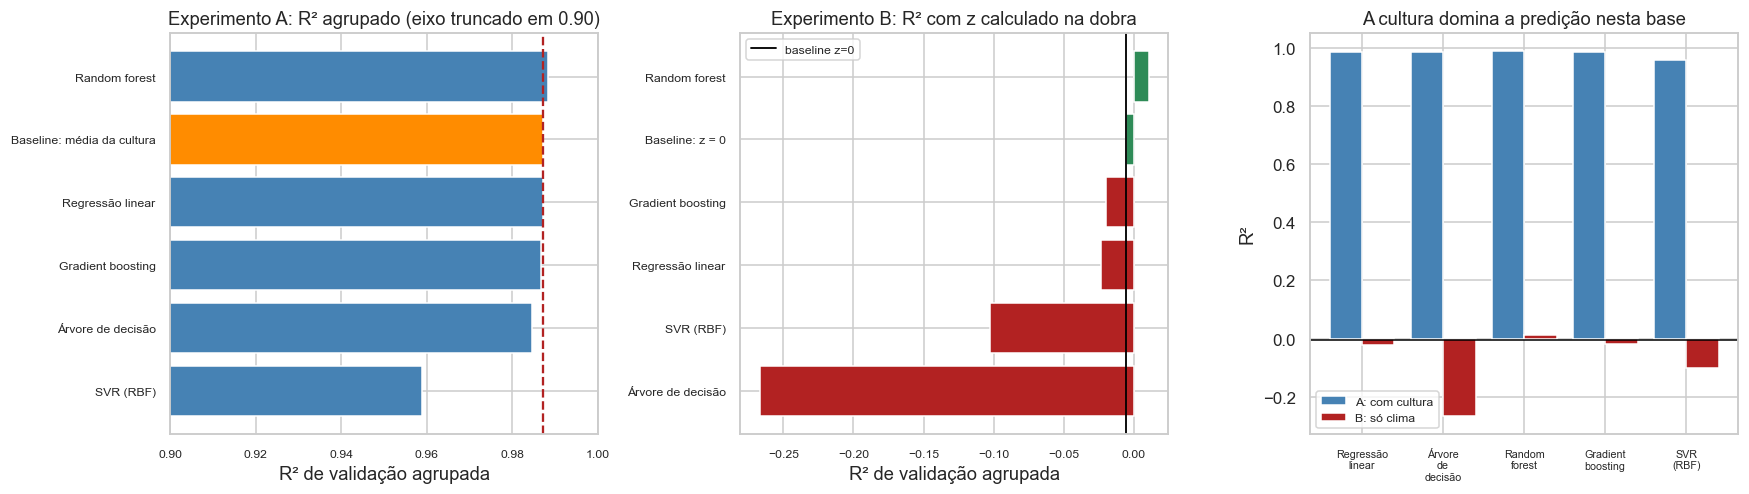

In [24]:
# Comparação visual dos dois experimentos
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# R² do experimento A contra o baseline
ordem_A = res_A.drop(index=['Baseline: média global']).sort_values('r2')
cores = ['darkorange' if 'Baseline' in i else 'steelblue' for i in ordem_A.index]
axes[0].barh(ordem_A.index, ordem_A['r2'], color=cores)
axes[0].set_xlim(0.90, 1.0)
axes[0].axvline(res_A.loc['Baseline: média da cultura', 'r2'], color='firebrick', ls='--', lw=1.5)
axes[0].set_title('Experimento A: R² agrupado (eixo truncado em 0.90)')
axes[0].set_xlabel('R² de validação agrupada')
axes[0].tick_params(labelsize=8)

# R² do experimento B
ordem_B = res_B.sort_values('r2_teste')
axes[1].barh(ordem_B.index, ordem_B['r2_teste'],
             color=['firebrick' if v < res_B.loc['Baseline: z = 0', 'r2_teste'] else 'seagreen' for v in ordem_B['r2_teste']])
axes[1].axvline(res_B.loc['Baseline: z = 0', 'r2_teste'], color='black', lw=1.2, label='baseline z=0')
axes[1].set_title('Experimento B: R² com z calculado na dobra')
axes[1].set_xlabel('R² de validação agrupada')
axes[1].tick_params(labelsize=8)
axes[1].legend(fontsize=8)

# O contraste entre os dois experimentos
modelos_nomes = list(construir_modelos().keys())
x = np.arange(len(modelos_nomes))
axes[2].bar(x - 0.2, [res_A.loc[m, 'r2'] for m in modelos_nomes], 0.4, label='A: com cultura', color='steelblue')
axes[2].bar(x + 0.2, [res_B.loc[m, 'r2_teste'] for m in modelos_nomes], 0.4, label='B: só clima', color='firebrick')
axes[2].axhline(res_B.loc['Baseline: z = 0', 'r2_teste'], color='black', lw=1)
axes[2].set_xticks(x)
axes[2].set_xticklabels([m.replace(' ', '\n') for m in modelos_nomes], fontsize=7)
axes[2].set_ylabel('R²')
axes[2].set_title('A cultura domina a predição nesta base')
axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()


## 7. Diagnóstico dos resíduos

Métricas agregadas escondem padrões de erro. Para interpretar resíduos de forma geral, uso previsões out-of-fold do melhor modelo do experimento A nas cinco dobras do `GroupKFold`. Cada observação é prevista por um modelo treinado sem o cenário climático correspondente.

In [25]:
# Diagnóstico de resíduos com previsões out-of-fold do melhor modelo do experimento A
melhor_nome = res_A.drop(index=['Baseline: média global', 'Baseline: média da cultura'])['rmse'].idxmin()
print(f'Melhor modelo do experimento A por RMSE: {melhor_nome}\n')

diag_oof = df[['cenario_climatico', 'cultura', ALVO]].rename(columns={ALVO: 'real'}).copy()
diag_oof['dobra'] = np.nan
diag_oof['previsto'] = np.nan
contador_diag_oof = pd.Series(0, index=df.index, dtype=int)

verificacao_diag_oof = []
metricas_diag_dobras = []
for dobra, (tr, te) in enumerate(CV.split(X_A, y_A, groups=GROUPS), start=1):
    cenarios_treino = set(GROUPS.iloc[tr])
    cenarios_teste = set(GROUPS.iloc[te])
    intersecao = cenarios_treino & cenarios_teste
    assert len(intersecao) == 0

    modelo_diag = Pipeline([('pre', pre_A), ('modelo', construir_modelos()[melhor_nome])])
    modelo_diag.fit(X_A.iloc[tr], y_A.iloc[tr])
    pred_teste = modelo_diag.predict(X_A.iloc[te])
    y_teste = y_A.iloc[te]
    idx_teste = X_A.iloc[te].index

    diag_oof.loc[idx_teste, 'dobra'] = dobra
    diag_oof.loc[idx_teste, 'previsto'] = pred_teste
    contador_diag_oof.loc[idx_teste] = contador_diag_oof.loc[idx_teste] + 1

    verificacao_diag_oof.append({
        'dobra': dobra,
        'linhas_teste': len(te),
        'cenários_teste': len(cenarios_teste),
        'interseção treino-teste': len(intersecao),
    })
    metricas_diag_dobras.append({
        'dobra': dobra,
        'r2': r2_score(y_teste, pred_teste),
        'rmse': root_mean_squared_error(y_teste, pred_teste),
        'mae': mean_absolute_error(y_teste, pred_teste),
        'mape': mape(y_teste, pred_teste),
    })

assert contador_diag_oof.eq(1).all()
assert diag_oof[['dobra', 'previsto']].notna().all().all()
assert np.isfinite(diag_oof['previsto']).all()

diag_oof['residuo'] = diag_oof['real'] - diag_oof['previsto']
diag_oof['erro_abs'] = diag_oof['residuo'].abs()
diag_oof['erro_pct'] = diag_oof['erro_abs'] / diag_oof['real'] * 100
assert np.isfinite(diag_oof[['residuo', 'erro_abs', 'erro_pct']]).all().all()

verificacao_diag_oof = pd.DataFrame(verificacao_diag_oof)
metricas_diag_dobras = pd.DataFrame(metricas_diag_dobras)
metricas_diag_oof = pd.Series({
    'r2': r2_score(diag_oof['real'], diag_oof['previsto']),
    'rmse': root_mean_squared_error(diag_oof['real'], diag_oof['previsto']),
    'mae': mean_absolute_error(diag_oof['real'], diag_oof['previsto']),
    'mape': mape(diag_oof['real'], diag_oof['previsto']),
}, name=melhor_nome).to_frame('valor')

print(f'Previsões OOF no diagnóstico: {contador_diag_oof.sum()} observações | mínimo por linha: {contador_diag_oof.min()} | máximo por linha: {contador_diag_oof.max()}')
print('Verificação do diagnóstico OOF: cenários_treino ∩ cenários_teste = ∅ em todas as dobras\n')
display(verificacao_diag_oof)

print('\nMétricas globais do diagnóstico OOF\n')
display(metricas_diag_oof.round(3))

print('\nMétricas por dobra do diagnóstico OOF\n')
display(metricas_diag_dobras.round(3))

Melhor modelo do experimento A por RMSE: Random forest



Previsões OOF no diagnóstico: 156 observações | mínimo por linha: 1 | máximo por linha: 1
Verificação do diagnóstico OOF: cenários_treino ∩ cenários_teste = ∅ em todas as dobras



,dobra,linhas_teste,cenários_teste,interseção treino-teste
0,1,32,8,0
1,2,32,8,0
2,3,32,8,0
3,4,32,8,0
4,5,28,7,0



Métricas globais do diagnóstico OOF



,valor
r2,0.988
rmse,7583.106
mae,4129.471
mape,11.190



Métricas por dobra do diagnóstico OOF



,dobra,r2,rmse,mae,mape
0,1,0.989,7542.713,4497.421,12.485
1,2,0.981,9585.094,4714.567,12.388
2,3,0.987,7973.095,4556.514,12.746
3,4,0.995,4898.984,3301.204,9.448
4,5,0.990,7090.654,3498.820,8.551


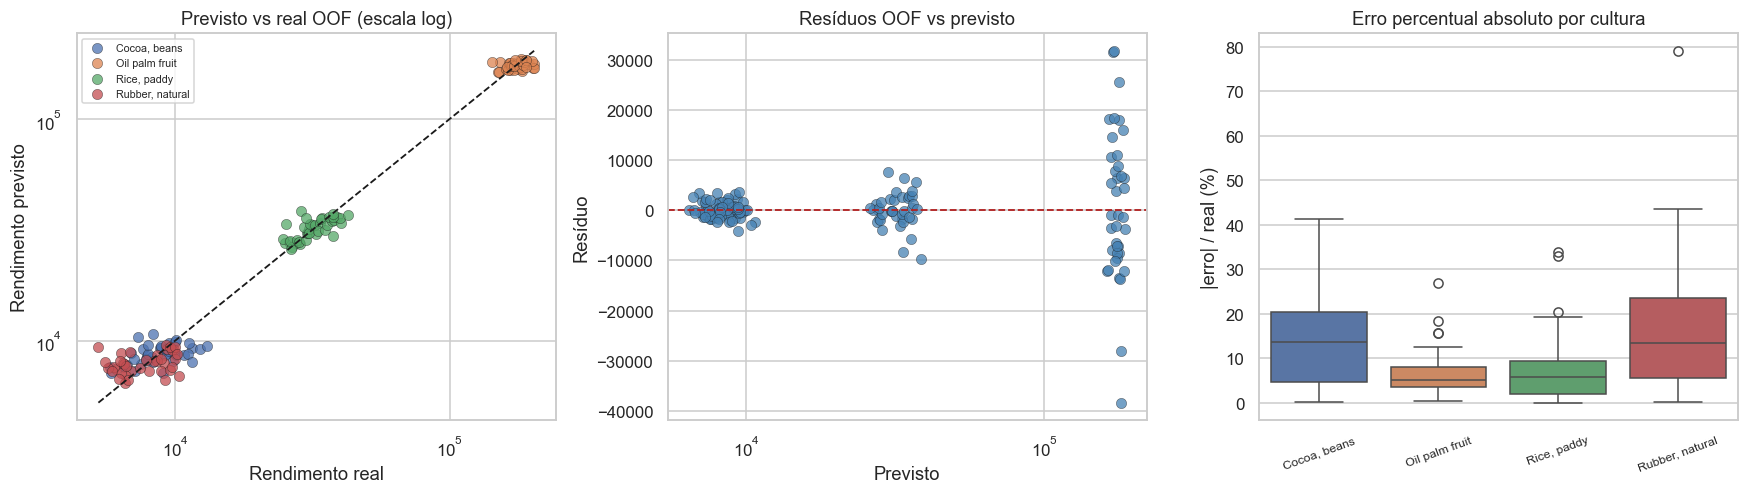

Erro percentual OOF por cultura:


,mean,median,max
cultura,,,
"Cocoa, beans",13.86,13.61,41.32
Oil palm fruit,6.67,5.16,26.91
"Rice, paddy",7.61,5.90,33.84
"Rubber, natural",16.62,13.47,79.15


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

for nome in sorted(diag_oof['cultura'].unique()):
    m = diag_oof['cultura'] == nome
    axes[0].scatter(diag_oof.loc[m, 'real'], diag_oof.loc[m, 'previsto'],
                    s=45, alpha=0.75, label=nome, edgecolor='k', lw=0.3)
lims = [min(diag_oof['real'].min(), diag_oof['previsto'].min()),
        max(diag_oof['real'].max(), diag_oof['previsto'].max())]
axes[0].plot(lims, lims, 'k--', lw=1.2)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Rendimento real'); axes[0].set_ylabel('Rendimento previsto')
axes[0].set_title('Previsto vs real OOF (escala log)')
axes[0].legend(fontsize=7)

axes[1].scatter(diag_oof['previsto'], diag_oof['residuo'], s=45, alpha=0.75,
                color='steelblue', edgecolor='k', lw=0.3)
axes[1].axhline(0, color='firebrick', ls='--', lw=1.2)
axes[1].set_xscale('log')
axes[1].set_xlabel('Previsto'); axes[1].set_ylabel('Resíduo')
axes[1].set_title('Resíduos OOF vs previsto')

# Erro percentual por cultura revela onde o modelo é de fato útil
por_cultura = diag_oof[['cultura', 'erro_pct']].copy()
sns.boxplot(data=por_cultura, x='cultura', y='erro_pct', ax=axes[2], hue='cultura', legend=False)
axes[2].set_title('Erro percentual absoluto por cultura')
axes[2].set_xlabel(''); axes[2].set_ylabel('|erro| / real (%)')
axes[2].tick_params(axis='x', rotation=20, labelsize=8)

plt.tight_layout(); plt.show()

print('Erro percentual OOF por cultura:')
display(por_cultura.groupby('cultura')['erro_pct'].agg(['mean', 'median', 'max']).round(2))

O gráfico de previsto contra real em escala logarítmica usa previsões OOF nas cinco dobras. Ele mostra quatro nuvens bem separadas, uma por cultura, com bom acerto do patamar geral e dispersão dentro de cada nuvem. Essa leitura vem de observações previstas por modelos que não viram o cenário climático correspondente.

A inspeção gráfica das previsões OOF não mostra um padrão evidente de resíduos suficiente para uma conclusão mais forte sobre heterocedasticidade ou viés sistemático. O diagnóstico sustenta uma leitura limitada: o modelo captura principalmente o patamar por cultura, mas ainda erra variação dentro das culturas.

O erro percentual varia entre culturas de forma coerente com o coeficiente de variação apurado no achado 3. Dendê, a cultura mais estável, apresenta o menor erro relativo. Borracha e cacau, as mais voláteis internamente, apresentam os maiores.

## 8. Importância das variáveis

Se a tese deste notebook estiver correta, a importância deve concentrar-se em `cultura` e o clima deve ficar próximo de zero. Testo com permutation importance em cada dobra do `GroupKFold`: o melhor modelo é ajustado no treino, e cada variável é embaralhada apenas nos dados não vistos daquela dobra. A métrica reportada é a queda de R², agregada entre as cinco dobras e as repetições das permutações. Prefiro esse método à importância nativa de árvores, que é enviesada a favor de variáveis com muitos valores distintos, ou seja, exatamente as contínuas de clima.

Verificação permutation importance: cenários_treino ∩ cenários_teste = ∅ em todas as dobras



,dobra,linhas_teste,cenários_teste,interseção treino-teste
0,1,32,8,0
1,2,32,8,0
2,3,32,8,0
3,4,32,8,0
4,5,28,7,0


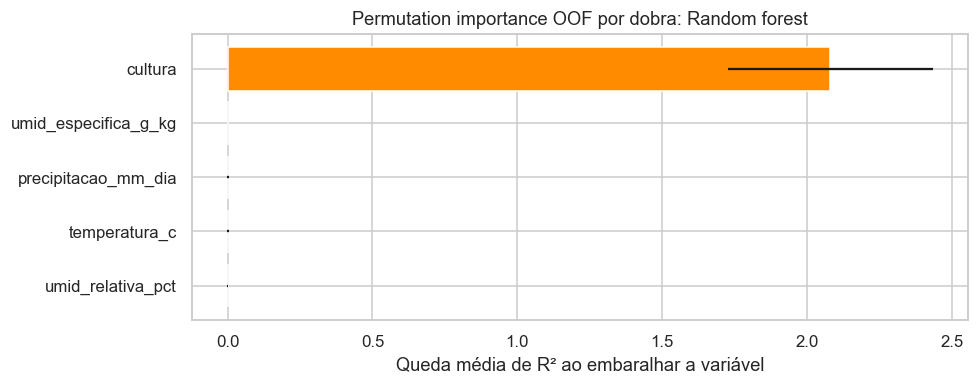

,queda_media_r2,desvio_dobras_repeticoes,mediana_queda_r2,minimo,maximo
variavel,,,,,
umid_relativa_pct,-0.0000,0.0019,-0.0003,-0.0032,0.0059
temperatura_c,0.0012,0.0023,0.0011,-0.0060,0.0065
precipitacao_mm_dia,0.0013,0.0033,0.0019,-0.0061,0.0082
umid_especifica_g_kg,0.0015,0.0014,0.0014,-0.0018,0.0052
cultura,2.0809,0.3529,2.0886,1.0650,2.8067


In [27]:
# Permutation importance agregada nas cinco dobras GroupKFold
importancias = []
verificacao_perm = []

for dobra, (tr, te) in enumerate(CV.split(X_A, y_A, groups=GROUPS), start=1):
    cenarios_treino = set(GROUPS.iloc[tr])
    cenarios_teste = set(GROUPS.iloc[te])
    intersecao = cenarios_treino & cenarios_teste
    assert len(intersecao) == 0

    modelo_perm = Pipeline([('pre', pre_A), ('modelo', construir_modelos()[melhor_nome])])
    modelo_perm.fit(X_A.iloc[tr], y_A.iloc[tr])
    imp = permutation_importance(
        modelo_perm,
        X_A.iloc[te],
        y_A.iloc[te],
        n_repeats=40,
        random_state=SEED,
        scoring='r2',
    )

    for pos, variavel in enumerate(X_A.columns):
        for repeticao, queda in enumerate(imp.importances[pos], start=1):
            importancias.append({
                'dobra': dobra,
                'variavel': variavel,
                'repeticao': repeticao,
                'queda_r2': queda,
            })

    verificacao_perm.append({
        'dobra': dobra,
        'linhas_teste': len(te),
        'cenários_teste': len(cenarios_teste),
        'interseção treino-teste': len(intersecao),
    })

imp_detalhe = pd.DataFrame(importancias)
verificacao_perm = pd.DataFrame(verificacao_perm)
assert len(imp_detalhe) == len(X_A.columns) * CV.get_n_splits() * 40
assert np.isfinite(imp_detalhe['queda_r2']).all()

tab_imp = (imp_detalhe
    .groupby('variavel')
    .agg(
        queda_media_r2=('queda_r2', 'mean'),
        desvio_dobras_repeticoes=('queda_r2', 'std'),
        mediana_queda_r2=('queda_r2', 'median'),
        minimo=('queda_r2', 'min'),
        maximo=('queda_r2', 'max'),
    )
    .sort_values('queda_media_r2', ascending=True)
)

print('Verificação permutation importance: cenários_treino ∩ cenários_teste = ∅ em todas as dobras\n')
display(verificacao_perm)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(tab_imp.index, tab_imp['queda_media_r2'], xerr=tab_imp['desvio_dobras_repeticoes'],
        color=['darkorange' if v == 'cultura' else 'steelblue' for v in tab_imp.index])
ax.set_xlabel('Queda média de R² ao embaralhar a variável')
ax.set_title(f'Permutation importance OOF por dobra: {melhor_nome}')
plt.tight_layout(); plt.show()

display(tab_imp.round(4))

In [28]:
# Quantificação direta: quanto vale cada bloco de variáveis?
# Comparo três conjuntos de features usando o mesmo algoritmo e a mesma validação agrupada.
conjuntos = {
    'Apenas cultura': (['cultura'], ColumnTransformer([('cat', OneHotEncoder(drop='first'), ['cultura'])])),
    'Apenas clima': (CLIMA, ColumnTransformer([('num', StandardScaler(), CLIMA)])),
    'Clima + cultura': (CLIMA + ['cultura'], pre_A),
}

comparacao = []
for rotulo, (cols, pre) in conjuntos.items():
    pipe = Pipeline([('pre', pre), ('modelo', construir_modelos()[melhor_nome])])
    cvres = cross_validate(pipe, df[cols], y_A, cv=CV, groups=GROUPS, scoring=SCORING)
    comparacao.append({'conjunto': rotulo, 'r2': cvres['test_r2'].mean(), 'rmse': -cvres['test_rmse'].mean()})

comp = pd.DataFrame(comparacao).set_index('conjunto')
comp['ganho_r2_vs_apenas_cultura'] = comp['r2'] - comp.loc['Apenas cultura', 'r2']
print(f'Ablação de features com {melhor_nome} | GroupKFold(5) por cenário climático\n')
display(comp.round(4))

Ablação de features com Random forest | GroupKFold(5) por cenário climático



,r2,rmse,ganho_r2_vs_apenas_cultura
conjunto,,,
Apenas cultura,0.9872,7851.6571,0.0000
Apenas clima,0.0010,70161.1959,-0.9862
Clima + cultura,0.9884,7418.1080,0.0012


### Achado 11: a ablação confirma o diagnóstico

Usar apenas a variável `cultura` já entrega praticamente todo o R². Usar apenas o clima entrega R² próximo de zero, equivalente a não extrair sinal preditivo útil. Adicionar clima sobre a cultura produz ganho marginal.

A permutation importance agregada por dobra aponta na mesma direção: embaralhar `cultura` causa a maior queda de R², enquanto as variáveis climáticas têm importâncias pequenas em relação à variabilidade observada entre permutações e dobras. Isso não prova inexistência de associação clima-rendimento; indica apenas que, neste protocolo preditivo e neste dataset, o sinal climático não se converteu em ganho robusto.

Em conjunto, a análise de sensibilidade ao índice do arquivo, a clusterização não supervisionada, a ablação de features e a permutation importance sustentam a mesma leitura operacional: há sinais bivariados instáveis, mas eles não se convertem em ganho preditivo robusto na validação agrupada.

## 9. Previsões out-of-fold por cenário climático

A seção abaixo substitui o antigo protocolo baseado na posição da linha. A posição da linha no arquivo não possui significado estatístico conhecido, então ela deixa de ser protocolo de validação.

Uso `GroupKFold` para gerar previsões out-of-fold (OOF): cada uma das 156 observações é prevista por um modelo treinado sem o cenário climático dela. Isso preserva os 39 cenários como grupos indivisíveis e permite calcular previsto × real, MAPE por cultura, MAE por cultura e faixas de referência de erro sem compartilhar cenário climático entre treino e teste.

In [29]:
# Previsões out-of-fold por cenário climático para o experimento A
modelos_nomes = list(construir_modelos().keys())
PREDITORES = ['Baseline'] + modelos_nomes

oof = df[['cenario_climatico', 'cultura', ALVO]].rename(columns={ALVO: 'real'}).copy()
oof['dobra'] = np.nan
for col in PREDITORES:
    oof[col] = np.nan

verificacao_oof = []
for dobra, (tr, te) in enumerate(CV.split(X_A, y_A, groups=GROUPS), start=1):
    cenarios_treino = set(GROUPS.iloc[tr])
    cenarios_teste = set(GROUPS.iloc[te])
    intersecao = cenarios_treino & cenarios_teste
    assert len(intersecao) == 0

    idx_teste = X_A.iloc[te].index
    oof.loc[idx_teste, 'dobra'] = dobra

    media_global_treino = y_A.iloc[tr].mean()
    medias_cultura_treino = df.iloc[tr].groupby('cultura')[ALVO].mean()
    oof.loc[idx_teste, 'Baseline'] = df.iloc[te]['cultura'].map(medias_cultura_treino).fillna(media_global_treino).values

    for nome, modelo in construir_modelos().items():
        pipe = Pipeline([('pre', pre_A), ('modelo', modelo)]).fit(X_A.iloc[tr], y_A.iloc[tr])
        oof.loc[idx_teste, nome] = pipe.predict(X_A.iloc[te])

    verificacao_oof.append({
        'dobra': dobra,
        'linhas_teste': len(te),
        'cenários_teste': len(cenarios_teste),
        'interseção treino-teste': len(intersecao),
    })

assert not oof[PREDITORES].isna().any().any()
assert oof['dobra'].notna().all()

verificacao_oof = pd.DataFrame(verificacao_oof)

linhas_oof = []
for col in PREDITORES:
    linhas_oof.append({
        'modelo': col,
        'r2': r2_score(oof['real'], oof[col]),
        'rmse': root_mean_squared_error(oof['real'], oof[col]),
        'mae': mean_absolute_error(oof['real'], oof[col]),
        'mape': mape(oof['real'], oof[col]),
    })

res_oof = pd.DataFrame(linhas_oof).set_index('modelo')
res_oof['vs_baseline_rmse_pct'] = (res_oof.loc['Baseline', 'rmse'] - res_oof['rmse']) / res_oof.loc['Baseline', 'rmse'] * 100

print('Verificação OOF: cenários_treino ∩ cenários_teste = ∅ em todas as dobras\n')
display(verificacao_oof)

print('\nMétricas agregadas das previsões out-of-fold por cenário climático\n')
display(res_oof.round(3))

Verificação OOF: cenários_treino ∩ cenários_teste = ∅ em todas as dobras



,dobra,linhas_teste,cenários_teste,interseção treino-teste
0,1,32,8,0
1,2,32,8,0
2,3,32,8,0
3,4,32,8,0
4,5,28,7,0



Métricas agregadas das previsões out-of-fold por cenário climático



,r2,rmse,mae,mape,vs_baseline_rmse_pct
modelo,,,,,
Baseline,0.987,7952.416,4856.997,14.038,0.000
Regressão linear,0.987,8002.744,5108.748,18.443,-0.633
Árvore de decisão,0.985,8689.572,4731.497,12.225,-9.270
Random forest,0.988,7583.106,4129.471,11.190,4.644
Gradient boosting,0.986,8197.906,4554.801,12.199,-3.087
SVR (RBF),0.957,14485.772,9651.726,59.567,-82.156


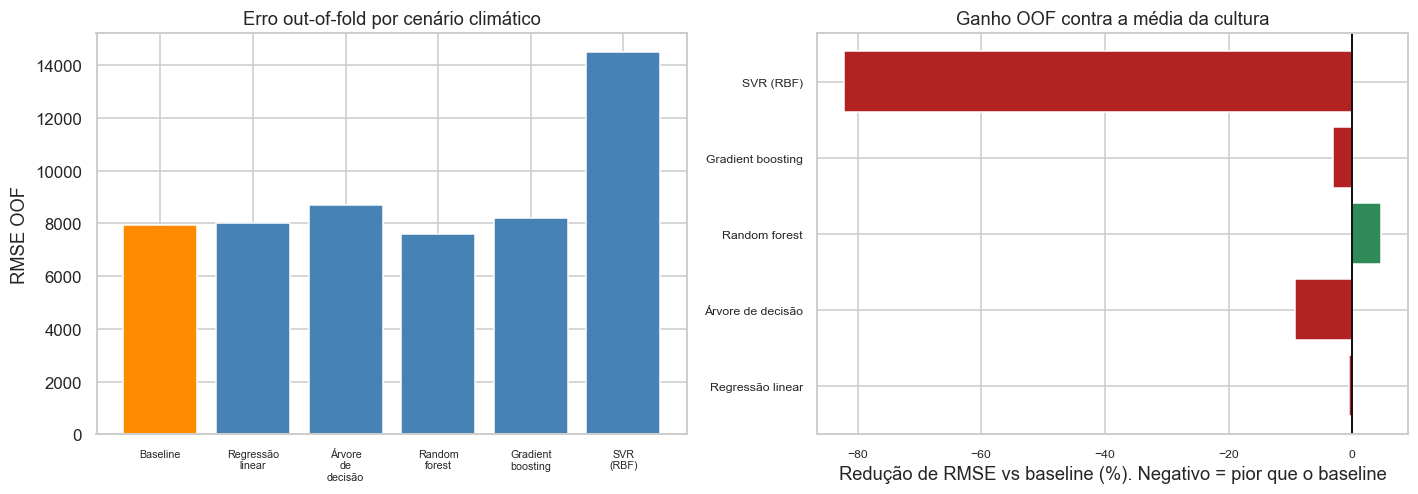

In [30]:
# Comparação OOF dos modelos contra o baseline
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

rotulos = PREDITORES
x = np.arange(len(rotulos))
rmse_oof = [res_oof.loc[m, 'rmse'] for m in rotulos]

cores = ['darkorange' if m == 'Baseline' else 'steelblue' for m in rotulos]
axes[0].bar(x, rmse_oof, color=cores)
axes[0].set_xticks(x); axes[0].set_xticklabels([r.replace(' ', '\n') for r in rotulos], fontsize=7)
axes[0].set_ylabel('RMSE OOF')
axes[0].set_title('Erro out-of-fold por cenário climático')

ganho = [res_oof.loc[m, 'vs_baseline_rmse_pct'] for m in modelos_nomes]
axes[1].barh(modelos_nomes, ganho, color=['seagreen' if g > 0 else 'firebrick' for g in ganho])
axes[1].axvline(0, color='black', lw=1.2)
axes[1].set_xlabel('Redução de RMSE vs baseline (%). Negativo = pior que o baseline')
axes[1].set_title('Ganho OOF contra a média da cultura')
axes[1].tick_params(labelsize=8)

plt.tight_layout(); plt.show()

### Achado 12: OOF por cenário é a referência de validação operacional

As previsões out-of-fold são a leitura mais direta da avaliação principal: cada linha foi prevista por um modelo que não viu o cenário climático correspondente durante o treinamento.

Esse protocolo substitui os antigos protocolos baseados na posição da linha e em dobras por linha. A comparação com o baseline passa a ser feita sem compartilhar cenários climáticos entre treino e teste.

A interpretação substantiva continua centrada no ganho incremental sobre a média da cultura. Se o ganho OOF for pequeno ou negativo, o modelo não demonstrou valor operacional além de reconhecer o patamar típico de cada cultura.

In [31]:
# Consolidação: tabela única com métricas group-aware
consolidado = pd.DataFrame({
    'R2 (A, GroupKFold)': [res_A.loc[m, 'r2'] for m in modelos_nomes],
    'R2 (B, GroupKFold)': [res_B.loc[m, 'r2_teste'] for m in modelos_nomes],
    'R2 OOF (A)': [res_oof.loc[m, 'r2'] for m in modelos_nomes],
    'R2 OOF (B)': [res_B_oof.loc[m, 'r2'] for m in modelos_nomes],
    'RMSE (A, GroupKFold)': [res_A.loc[m, 'rmse'] for m in modelos_nomes],
    'RMSE OOF (A)': [res_oof.loc[m, 'rmse'] for m in modelos_nomes],
    'RMSE OOF (B z)': [res_B_oof.loc[m, 'rmse'] for m in modelos_nomes],
    'MAPE OOF (A) %': [res_oof.loc[m, 'mape'] for m in modelos_nomes],
}, index=modelos_nomes)

base_row = pd.DataFrame({
    'R2 (A, GroupKFold)': [res_A.loc['Baseline: média da cultura', 'r2']],
    'R2 (B, GroupKFold)': [res_B.loc['Baseline: z = 0', 'r2_teste']],
    'R2 OOF (A)': [res_oof.loc['Baseline', 'r2']],
    'R2 OOF (B)': [res_B_oof.loc['Baseline: z = 0', 'r2']],
    'RMSE (A, GroupKFold)': [res_A.loc['Baseline: média da cultura', 'rmse']],
    'RMSE OOF (A)': [res_oof.loc['Baseline', 'rmse']],
    'RMSE OOF (B z)': [res_B_oof.loc['Baseline: z = 0', 'rmse']],
    'MAPE OOF (A) %': [res_oof.loc['Baseline', 'mape']],
}, index=['Baseline: cultura / z=0'])

final = pd.concat([base_row, consolidado])
print('QUADRO CONSOLIDADO COM VALIDAÇÃO AGRUPADA POR CENÁRIO CLIMÁTICO\n')
display(final.round(3))

print('\nLeitura: a coluna "R2 (B, GroupKFold)" responde à pergunta de negócio sobre clima isolado sem vazamento do alvo.')
print('As métricas OOF do experimento A são a referência operacional para previsto × real e faixas de referência de erro.')
print('As métricas OOF do experimento B medem a previsão do desvio em relação ao padrão da cultura aprendido no treino.')


QUADRO CONSOLIDADO COM VALIDAÇÃO AGRUPADA POR CENÁRIO CLIMÁTICO



,"R2 (A, GroupKFold)","R2 (B, GroupKFold)",R2 OOF (A),R2 OOF (B),"RMSE (A, GroupKFold)",RMSE OOF (A),RMSE OOF (B z),MAPE OOF (A) %
Baseline: cultura / z=0,0.987,-0.006,0.987,-0.000,7839.948,7952.416,1.009,14.038
Regressão linear,0.987,-0.024,0.987,-0.005,7873.869,8002.744,1.011,18.443
Árvore de decisão,0.985,-0.267,0.985,-0.210,8649.646,8689.572,1.109,12.225
Random forest,0.988,0.011,0.988,0.019,7418.108,7583.106,0.999,11.190
Gradient boosting,0.987,-0.020,0.986,0.007,7943.422,8197.906,1.005,12.199
SVR (RBF),0.959,-0.103,0.957,-0.034,13336.754,14485.772,1.025,59.567



Leitura: a coluna "R2 (B, GroupKFold)" responde à pergunta de negócio sobre clima isolado sem vazamento do alvo.
As métricas OOF do experimento A são a referência operacional para previsto × real e faixas de referência de erro.
As métricas OOF do experimento B medem a previsão do desvio em relação ao padrão da cultura aprendido no treino.


In [32]:
# Ficha consolidada por modelo, cruzando as avaliações group-aware.
# Fecha o requisito de "avaliar o modelo com métricas pertinentes ao problema"
# com um veredito por algoritmo, não apenas uma tabela agregada.

base_gkf = res_A.loc['Baseline: média da cultura', 'r2']
base_oof = res_oof.loc['Baseline', 'r2']
base_b = res_B.loc['Baseline: z = 0', 'r2_teste']

print('=' * 86)
print('FICHA DE AVALIAÇÃO POR MODELO'.center(86))
print('=' * 86)
print(f'Baseline B z=0, medido nas dobras: R² = {base_b:+.4f} | RMSE z = {res_B.loc["Baseline: z = 0", "rmse"]:.3f}')

for i, nome in enumerate(modelos_nomes, start=1):
    r2a = res_A.loc[nome, 'r2']
    r2b = res_B.loc[nome, 'r2_teste']
    r2o = res_oof.loc[nome, 'r2']
    r2bo = res_B_oof.loc[nome, 'r2']
    gap = res_B.loc[nome, 'r2_treino'] - res_B.loc[nome, 'r2_teste']

    supera_gkf = 'sim' if r2a > base_gkf else 'NÃO'
    supera_oof = 'sim' if r2o > base_oof else 'NÃO'
    supera_b = 'sim' if r2b > base_b else 'NÃO'

    print(f'\n[{i}] {nome}  ({FAMILIAS[nome]})')
    print(f'    Experimento A, GroupKFold     R² = {r2a:+.4f}   RMSE = {res_A.loc[nome, "rmse"]:>9,.0f}   MAE = {res_A.loc[nome, "mae"]:>9,.0f}')
    print(f'    Experimento B, GroupKFold     R² = {r2b:+.4f}   RMSE z = {res_B.loc[nome, "rmse"]:.3f}   gap treino-teste = {gap:+.3f}')
    print(f'    OOF A por cenário climático   R² = {r2o:+.4f}   RMSE = {res_oof.loc[nome, "rmse"]:>9,.0f}   MAPE = {res_oof.loc[nome, "mape"]:.2f}%')
    print(f'    OOF B, alvo z por dobra       R² = {r2bo:+.4f}   RMSE z = {res_B_oof.loc[nome, "rmse"]:.3f}')
    print(f'    Supera o baseline A GroupKFold? {supera_gkf}')
    print(f'    Supera o baseline A OOF?        {supera_oof}')
    print(f'    Supera o baseline B z=0?        {supera_b}')

print('\n' + '=' * 86)
n_sup_gkf = sum(1 for n in modelos_nomes if res_A.loc[n, 'r2'] > base_gkf)
n_sup_oof = sum(1 for n in modelos_nomes if res_oof.loc[n, 'r2'] > base_oof)
n_sup_b = sum(1 for n in modelos_nomes if res_B.loc[n, 'r2_teste'] > base_b)
print(f'Modelos que superam o baseline A em GroupKFold : {n_sup_gkf} de {len(modelos_nomes)}')
print(f'Modelos que superam o baseline A em OOF        : {n_sup_oof} de {len(modelos_nomes)}')
print(f'Modelos que superam o baseline B z=0           : {n_sup_b} de {len(modelos_nomes)}')
print('=' * 86)


                            FICHA DE AVALIAÇÃO POR MODELO                             
Baseline B z=0, medido nas dobras: R² = -0.0057 | RMSE z = 0.997

[1] Regressão linear  (Linear paramétrica)
    Experimento A, GroupKFold     R² = +0.9870   RMSE =     7,874   MAE =     5,091
    Experimento B, GroupKFold     R² = -0.0236   RMSE z = 0.999   gap treino-teste = +0.131
    OOF A por cenário climático   R² = +0.9870   RMSE =     8,003   MAPE = 18.44%
    OOF B, alvo z por dobra       R² = -0.0049   RMSE z = 1.011
    Supera o baseline A GroupKFold? NÃO
    Supera o baseline A OOF?        NÃO
    Supera o baseline B z=0?        NÃO

[2] Árvore de decisão  (Particionamento único)
    Experimento A, GroupKFold     R² = +0.9846   RMSE =     8,650   MAE =     4,743
    Experimento B, GroupKFold     R² = -0.2670   RMSE z = 1.100   gap treino-teste = +0.664
    OOF A por cenário climático   R² = +0.9847   RMSE =     8,690   MAPE = 12.22%
    OOF B, alvo z por dobra       R² = -0.2096   RMSE z 

## 10. Previsão de rendimento da safra

As seções 6 a 9 identificaram qual modelo teve melhor desempenho no protocolo adotado. Esta seção entrega o que o enunciado pede de forma literal: dadas as condições, prever qual será o rendimento da safra.

São três artefatos, todos sem assumir cronologia na ordem das linhas.

**10.1. Previsto contra real OOF.** As previsões out-of-fold por cenário climático geradas na seção 9 são usadas para comparar previsto × real, MAPE por cultura, MAE por cultura e referências de erro. Cada previsão vem de um modelo que não viu aquele cenário climático no treino.

**10.2. Função de previsão reutilizável.** `prever_rendimento` recebe cultura e condições climáticas e devolve a previsão dos cinco modelos e do baseline. Serve para operar o modelo e, sobretudo, para testar sua sensibilidade ao clima.

**10.3. Cenários sintéticos de sensibilidade.** Em vez de projetar um período futuro inexistente no dataset, aplico a função a cenários construídos pelos quantis marginais das quatro variáveis climáticas: percentil 10, mediana e percentil 90. Cada componente fica dentro de sua faixa marginal observada, mas a combinação multivariada pode não existir entre os 39 cenários reais.

**Decisão sobre a unidade.** Mantenho o alvo na unidade original do arquivo em toda a modelagem, conforme registrado na seção 1. Nesta seção, e apenas nela, apresento também a escala convertida para t/ha adotada pelo projeto, dividindo por 10.000. A conversão é linear, não altera o CSV original e não altera métricas relativas como R² ou a ordenação dos modelos. Ela é usada para leitura operacional, com rastreabilidade para o valor original.

In [33]:
# 10.1. Previsões out-of-fold por cenário climático: previsto contra real
FATOR_CONVERSAO_T_HA = 10_000  # decisão metodológica de apresentação; não altera o CSV original.

prev = oof.copy()

# Erro percentual e erro absoluto por cultura, para cada preditor
mape_cultura = pd.DataFrame({
    col: prev.groupby('cultura', group_keys=False).apply(lambda g, c=col: mape(g['real'], g[c]))
    for col in PREDITORES
})
mae_cultura = pd.DataFrame({
    col: prev.groupby('cultura', group_keys=False).apply(lambda g, c=col: np.abs(g['real'] - g[c]).mean())
    for col in PREDITORES
})

print('MAPE por cultura nas previsões OOF por cenário climático (%)\n')
display(mape_cultura.round(2))

print('\nMAE por cultura nas previsões OOF, na unidade original do arquivo\n')
display(mae_cultura.round(1))

print('\nPrevisto contra real OOF, em t/ha adotado, para todas as observações')
print('(colunas: real e previsão de cada preditor)\n')
tabela_prev = prev.set_index(['cenario_climatico', 'cultura', 'dobra'])[['real'] + PREDITORES] / FATOR_CONVERSAO_T_HA
display(tabela_prev.round(2))

MAPE por cultura nas previsões OOF por cenário climático (%)



,Baseline,Regressão linear,Árvore de decisão,Random forest,Gradient boosting,SVR (RBF)
cultura,,,,,,
"Cocoa, beans",16.58,25.65,16.07,13.86,16.36,95.14
Oil palm fruit,7.21,7.14,7.86,6.67,7.19,8.17
"Rice, paddy",12.78,11.75,7.58,7.61,9.19,22.55
"Rubber, natural",19.57,29.22,17.39,16.62,16.06,112.41



MAE por cultura nas previsões OOF, na unidade original do arquivo



,Baseline,Regressão linear,Árvore de decisão,Random forest,Gradient boosting,SVR (RBF)
cultura,,,,,,
"Cocoa, beans",1416.1,2191.0,1416.4,1235.9,1475.4,8571.0
Oil palm fruit,12512.6,12352.1,13740.1,11653.0,12616.1,14640.6
"Rice, paddy",4038.6,3679.7,2474.0,2428.0,2950.6,6954.2
"Rubber, natural",1460.8,2212.2,1295.6,1201.0,1177.1,8441.1



Previsto contra real OOF, em t/ha adotado, para todas as observações
(colunas: real e previsão de cada preditor)



,,,real,Baseline,Regressão linear,Árvore de decisão,Random forest,Gradient boosting,SVR (RBF)
cenario_climatico,cultura,dobra,,,,,,,
0,"Cocoa, beans",4.0,1.16,0.87,0.95,0.99,0.93,0.96,-0.07
1,"Cocoa, beans",3.0,1.13,0.89,0.81,1.01,0.97,0.93,5.73
2,"Cocoa, beans",2.0,0.95,0.89,1.27,1.03,0.97,1.02,1.89
3,"Cocoa, beans",1.0,0.93,0.90,0.97,0.94,0.88,0.96,3.66
4,"Cocoa, beans",5.0,0.88,0.89,0.80,0.91,0.93,0.95,1.19
...,...,...,...,...,...,...,...,...,...
34,"Rubber, natural",5.0,0.67,0.78,0.83,0.68,0.67,0.72,-0.50
35,"Rubber, natural",4.0,0.62,0.77,0.89,0.72,0.67,0.69,1.25
36,"Rubber, natural",3.0,0.68,0.78,1.12,0.92,0.89,0.81,4.20


In [34]:
# 10.2. Função de previsão reutilizável
# Modelos reajustados sobre a base completa para gerar previsões em condições informadas.
# O erro de referência continua sendo o OOF medido em 10.1.

modelos_full = {
    nome: Pipeline([('pre', pre_A), ('modelo', modelo)]).fit(X_A, y_A)
    for nome, modelo in construir_modelos().items()
}
medias_cultura = df.groupby('cultura')[ALVO].mean()


def prever_rendimento(cultura, precipitacao_mm_dia, umid_especifica_g_kg,
                      umid_relativa_pct, temperatura_c):
    """Prevê o rendimento da safra para uma condição informada.

    Devolve um DataFrame com a previsão do baseline e dos cinco modelos,
    no valor original do CSV e na escala t/ha adotada pelo projeto.
    """
    if cultura not in medias_cultura.index:
        raise ValueError(f'Cultura desconhecida: {cultura}. Válidas: {list(medias_cultura.index)}')

    entrada = pd.DataFrame([{
        'precipitacao_mm_dia': precipitacao_mm_dia,
        'umid_especifica_g_kg': umid_especifica_g_kg,
        'umid_relativa_pct': umid_relativa_pct,
        'temperatura_c': temperatura_c,
        'cultura': cultura,
    }])[CLIMA + ['cultura']]

    saida = {'Baseline': float(medias_cultura[cultura])}
    for nome, pipe in modelos_full.items():
        saida[nome] = float(pipe.predict(entrada)[0])

    tab = pd.DataFrame({'previsto_valor_original': saida})
    tab['previsto_t_ha_adotado'] = tab['previsto_valor_original'] / FATOR_CONVERSAO_T_HA
    return tab


# Demonstração de uso
exemplo = prever_rendimento(
    cultura='Rice, paddy',
    precipitacao_mm_dia=2300.0,
    umid_especifica_g_kg=18.0,
    umid_relativa_pct=84.0,
    temperatura_c=26.2,
)
print('Exemplo: arroz sob condições próximas da mediana observada\n')
display(exemplo.round(2))

Exemplo: arroz sob condições próximas da mediana observada



,previsto_valor_original,previsto_t_ha_adotado
Baseline,32099.67,3.21
Regressão linear,27409.86,2.74
Árvore de decisão,25792.20,2.58
Random forest,27581.73,2.76
Gradient boosting,27568.53,2.76
SVR (RBF),29667.51,2.97


In [35]:
# Teste de sensibilidade: a previsão reage ao clima?
# Monto cenários sintéticos com quantis marginais das quatro variáveis climáticas.
# Cada componente está na faixa marginal observada, mas a combinação pode não existir na base.

cenarios = {
    'P10 marginal do clima': clima_ref[CLIMA].quantile(0.10),
    'Mediana marginal do clima': clima_ref[CLIMA].median(),
    'P90 marginal do clima': clima_ref[CLIMA].quantile(0.90),
}

blocos = []
for cultura in sorted(df['cultura'].unique()):
    linha = {}
    for rotulo, c in cenarios.items():
        t = prever_rendimento(cultura, c['precipitacao_mm_dia'], c['umid_especifica_g_kg'],
                              c['umid_relativa_pct'], c['temperatura_c'])
        linha[rotulo] = t['previsto_t_ha_adotado']
    bloco = pd.DataFrame(linha)
    bloco['variacao_pct'] = (bloco['P90 marginal do clima'] - bloco['P10 marginal do clima']).abs() / bloco['Mediana marginal do clima'] * 100
    bloco['cultura'] = cultura
    blocos.append(bloco.reset_index().rename(columns={'index': 'preditor'}))

sensibilidade = (pd.concat(blocos).set_index(['cultura', 'preditor'])
                 .reindex(pd.MultiIndex.from_product(
                     [sorted(df['cultura'].unique()), PREDITORES],
                     names=['cultura', 'preditor'])))
print('Previsão em t/ha adotado para cenários sintéticos P10/mediana/P90 marginais, com a cultura fixa\n')
display(sensibilidade.round(3))

print('\nAmplitude da previsão entre P10 e P90 marginais, em % da previsão na mediana marginal:')
print(sensibilidade.groupby('preditor')['variacao_pct'].mean().round(2).to_string())

Previsão em t/ha adotado para cenários sintéticos P10/mediana/P90 marginais, com a cultura fixa



P10 marginal do clima  \
cultura         preditor                                   
Cocoa, beans    Baseline                           0.888   
                Regressão linear                   1.399   
                Árvore de decisão                  0.904   
                Random forest                      0.962   
                Gradient boosting                  1.027   
                SVR (RBF)                          1.240   
Oil palm fruit  Baseline                          17.580   
                Regressão linear                  18.091   
                Árvore de decisão                 16.497   
                Random forest                     17.821   
                Gradient boosting                 18.155   
                SVR (RBF)                         19.036   
Rice, paddy     Baseline                           3.210   
                Regressão linear                   3.720   
                Árvore de decisão                  2.801   
                Random forest                      2.750   
                Gradient boosting                  2.816   
                SVR (RBF)                          3.114   
Rubber, natural Baseline                           0.782   
                Regressão linear                   1.293   
                Árvore de decisão                  0.948   
                Random forest                      0.931   
                Gradient boosting                  0.944   
                SVR (RBF)                          1.096   

                                   Mediana marginal do clima  \
cultura         preditor                                       
Cocoa, beans    Baseline                               0.888   
                Regressão linear                       1.573   
                Árvore de decisão                      0.814   
                Random forest                          0.851   
                Gradient boosting                      0.893   
                SVR (RBF)                              0.784   
Oil palm fruit  Baseline                              17.580   
                Regressão linear                      18.265   
                Árvore de decisão                     17.243   
                Random forest                         17.232   
                Gradient boosting                     17.213   
                SVR (RBF)                             16.669   
Rice, paddy     Baseline                               3.210   
                Regressão linear                       3.894   
                Árvore de decisão                      3.188   
                Random forest                          3.203   
                Gradient boosting                      3.233   
                SVR (RBF)                              2.900   
Rubber, natural Baseline                               0.782   
                Regressão linear                       1.467   
                Árvore de decisão                      0.704   
                Random forest                          0.825   
                Gradient boosting                      0.790   
                SVR (RBF)                              0.798   

                                   P90 marginal do clima  variacao_pct  
cultura         preditor                                                
Cocoa, beans    Baseline                           0.888         0.000  
                Regressão linear                  -1.258       168.963  
                Árvore de decisão                  0.960         6.826  
                Random forest                      0.939         2.679  
                Gradient boosting                  1.082         6.084  
                SVR (RBF)                          2.290       133.956  
Oil palm fruit  Baseline                          17.580         0.000  
                Regressão linear                  15.434        14.547  
                Árvore de decisão                 19.075        14.952  
      


Amplitude da previsão entre P10 e P90 marginais, em % da previsão na mediana marginal:
preditor
Baseline               0.00
Gradient boosting     13.64
Random forest         12.75
Regressão linear     108.22
SVR (RBF)             76.51
Árvore de decisão     12.28


In [36]:
# 10.3. Cenários sintéticos de sensibilidade, sem projeção temporal
# Como não há data nem ano, não projeto próximo período nem extrapolo tendência.
# Uso quantis marginais; a combinação multivariada pode não corresponder a cenário real.

CENARIOS_OPERACIONAIS = {
    'P10 marginal do clima': clima_ref[CLIMA].quantile(0.10).to_dict(),
    'Mediana marginal do clima': clima_ref[CLIMA].median().to_dict(),
    'P90 marginal do clima': clima_ref[CLIMA].quantile(0.90).to_dict(),
}

print('Condições climáticas dos cenários sintéticos de sensibilidade\n')
display(pd.DataFrame(CENARIOS_OPERACIONAIS).T.round(2))

linhas_cenarios = []
for cultura in sorted(df['cultura'].unique()):
    for rotulo, cen in CENARIOS_OPERACIONAIS.items():
        t = prever_rendimento(cultura, cen['precipitacao_mm_dia'], cen['umid_especifica_g_kg'],
                              cen['umid_relativa_pct'], cen['temperatura_c'])
        for preditor, v in t['previsto_t_ha_adotado'].items():
            linhas_cenarios.append({'cultura': cultura, 'cenario': rotulo,
                                    'preditor': preditor, 'previsto_t_ha_adotado': v})

previsao_cenarios = pd.DataFrame(linhas_cenarios)
col_cenario_ref = 'Mediana marginal do clima'
cols_cenarios = list(CENARIOS_OPERACIONAIS)
tabela_cenarios = (previsao_cenarios.pivot_table(index=['cultura', 'preditor'], columns='cenario',
                                                values='previsto_t_ha_adotado')
                   .reindex(pd.MultiIndex.from_product(
                       [sorted(df['cultura'].unique()), PREDITORES],
                       names=['cultura', 'preditor'])))

# Faixa de referência: MAE OOF por cultura medido em 10.1, na mesma unidade
faixa = (mae_cultura / FATOR_CONVERSAO_T_HA).stack().rename('faixa_mae_oof_t_ha_adotado')
faixa.index = faixa.index.set_names(['cultura', 'preditor'])
tabela_cenarios = tabela_cenarios.join(faixa)
tabela_cenarios['amplitude_cenarios'] = tabela_cenarios[cols_cenarios].max(axis=1) - tabela_cenarios[cols_cenarios].min(axis=1)

print('\nPrevisão por cenário sintético em t/ha adotado, com faixa de referência baseada em ±1 MAE OOF, sem cobertura probabilística definida\n')
display(tabela_cenarios.round(3))

# A escolha do modelo importa mais ou menos que o erro do próprio modelo?
ESTAVEIS = ['Baseline', 'Árvore de decisão', 'Random forest', 'Gradient boosting']
disp_total = tabela_cenarios.groupby('cultura')[col_cenario_ref].agg(lambda s: s.max() - s.min())
disp_estaveis = (tabela_cenarios.reset_index()
                 .query('preditor in @ESTAVEIS')
                 .groupby('cultura')[col_cenario_ref].agg(lambda s: s.max() - s.min()))
faixa_base = tabela_cenarios.xs('Baseline', level='preditor')['faixa_mae_oof_t_ha_adotado']

comparativo = pd.DataFrame({
    'dispersao_6_preditores': disp_total,
    'dispersao_sem_lin_e_svr': disp_estaveis,
    'faixa_mae_oof_do_baseline': faixa_base,
})
print('\nDispersão entre preditores contra a faixa de referência MAE OOF do baseline, em t/ha adotado\n')
display(comparativo.round(3))

Condições climáticas dos cenários sintéticos de sensibilidade



,precipitacao_mm_dia,umid_especifica_g_kg,umid_relativa_pct,temperatura_c
P10 marginal do clima,2099.79,17.72,83.44,25.92
Mediana marginal do clima,2424.55,18.27,84.85,26.13
P90 marginal do clima,2898.66,18.50,86.02,26.47



Previsão por cenário sintético em t/ha adotado, com faixa de referência baseada em ±1 MAE OOF, sem cobertura probabilística definida



Mediana marginal do clima  \
cultura         preditor                                       
Cocoa, beans    Baseline                               0.888   
                Regressão linear                       1.573   
                Árvore de decisão                      0.814   
                Random forest                          0.851   
                Gradient boosting                      0.893   
                SVR (RBF)                              0.784   
Oil palm fruit  Baseline                              17.580   
                Regressão linear                      18.265   
                Árvore de decisão                     17.243   
                Random forest                         17.232   
                Gradient boosting                     17.213   
                SVR (RBF)                             16.669   
Rice, paddy     Baseline                               3.210   
                Regressão linear                       3.894   
                Árvore de decisão                      3.188   
                Random forest                          3.203   
                Gradient boosting                      3.233   
                SVR (RBF)                              2.900   
Rubber, natural Baseline                               0.782   
                Regressão linear                       1.467   
                Árvore de decisão                      0.704   
                Random forest                          0.825   
                Gradient boosting                      0.790   
                SVR (RBF)                              0.798   

                                   P10 marginal do clima  \
cultura         preditor                                   
Cocoa, beans    Baseline                           0.888   
                Regressão linear                   1.399   
                Árvore de decisão                  0.904   
                Random forest                      0.962   
                Gradient boosting                  1.027   
                SVR (RBF)                          1.240   
Oil palm fruit  Baseline                          17.580   
                Regressão linear                  18.091   
                Árvore de decisão                 16.497   
                Random forest                     17.821   
                Gradient boosting                 18.155   
                SVR (RBF)                         19.036   
Rice, paddy     Baseline                           3.210   
                Regressão linear                   3.720   
                Árvore de decisão                  2.801   
                Random forest                      2.750   
                Gradient boosting                  2.816   
                SVR (RBF)                          3.114   
Rubber, natural Baseline                           0.782   
                Regressão linear                   1.293   
                Árvore de decisão                  0.948   
                Random forest                      0.931   
                Gradient boosting                  0.944   
                SVR (RBF)                          1.096   

                                   P90 marginal do clima  \
cultura         preditor                                   
Cocoa, beans    Baseline                           0.888   
                Regressão linear                  -1.258   
                Árvore de decisão                  0.960   
                Random forest                      0.939   
                Gradient boosting                  1.082   
                SVR (RBF)                          2.290   
Oil palm fruit  Baseline                          17.580   
                Regressão linear                  15.434   
                Árvore de decisão                 19.075   
                Random forest                     18.947   
                Gradient boosting                 19.984   
                SVR (RBF)    


Dispersão entre preditores contra a faixa de referência MAE OOF do baseline, em t/ha adotado



,dispersao_6_preditores,dispersao_sem_lin_e_svr,faixa_mae_oof_do_baseline
cultura,,,
"Cocoa, beans",0.789,0.079,0.142
Oil palm fruit,1.595,0.368,1.251
"Rice, paddy",0.994,0.045,0.404
"Rubber, natural",0.762,0.120,0.146


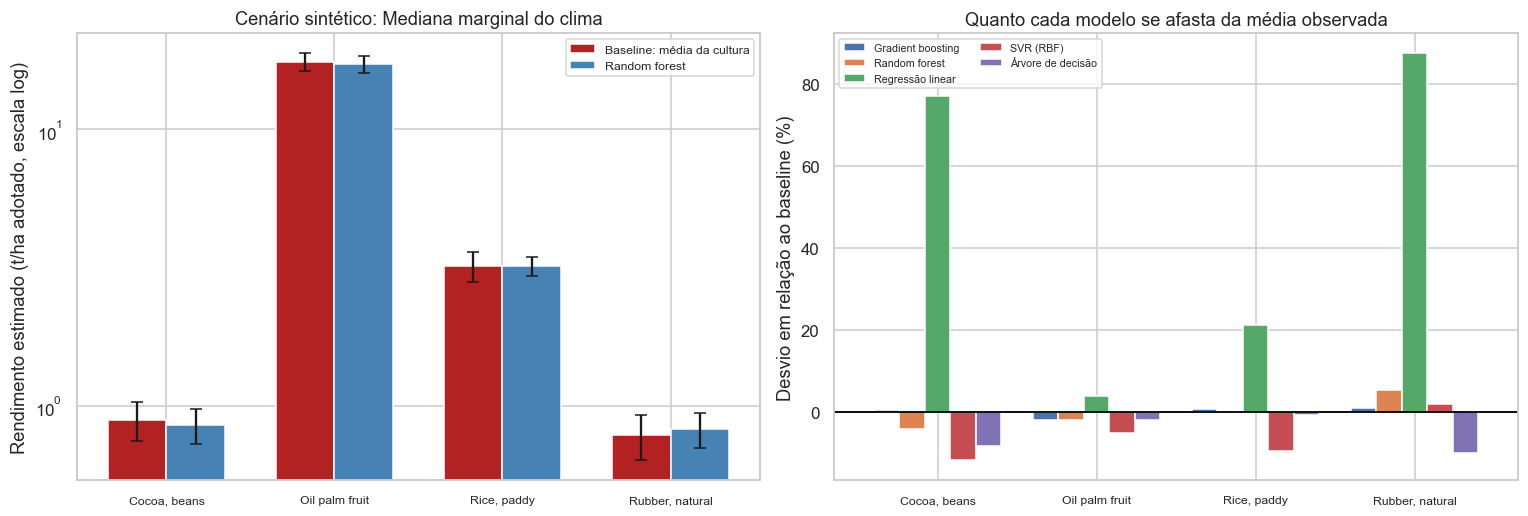

In [37]:
# Visualização dos cenários sintéticos de sensibilidade
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

culturas_ord = sorted(df['cultura'].unique())
x = np.arange(len(culturas_ord))
largura = 0.35

base_cen = tabela_cenarios.xs('Baseline', level='preditor')
melhor_cen = tabela_cenarios.xs(melhor_nome, level='preditor')
col_cen = col_cenario_ref

axes[0].bar(x - largura/2, base_cen.loc[culturas_ord, col_cen], largura,
            yerr=base_cen.loc[culturas_ord, 'faixa_mae_oof_t_ha_adotado'], capsize=4,
            label='Baseline: média da cultura', color='firebrick')
axes[0].bar(x + largura/2, melhor_cen.loc[culturas_ord, col_cen], largura,
            yerr=melhor_cen.loc[culturas_ord, 'faixa_mae_oof_t_ha_adotado'], capsize=4,
            label=melhor_nome, color='steelblue')
axes[0].set_yscale('log')
axes[0].set_xticks(x); axes[0].set_xticklabels(culturas_ord, fontsize=8)
axes[0].set_ylabel('Rendimento estimado (t/ha adotado, escala log)')
axes[0].set_title(f'Cenário sintético: {col_cen}')
axes[0].legend(fontsize=8)

# Painel 2: dispersão entre os cinco modelos, relativa ao baseline
disp = tabela_cenarios[col_cen].unstack('preditor')
rel = (disp.drop(columns='Baseline').sub(disp['Baseline'], axis=0)
       .div(disp['Baseline'], axis=0) * 100)
rel.loc[culturas_ord].plot(kind='bar', ax=axes[1], width=0.8)
axes[1].axhline(0, color='black', lw=1.2)
axes[1].set_ylabel('Desvio em relação ao baseline (%)')
axes[1].set_xlabel('')
axes[1].set_title('Quanto cada modelo se afasta da média observada')
axes[1].tick_params(axis='x', labelrotation=0, labelsize=8)
axes[1].legend(fontsize=7, ncol=2)

plt.tight_layout(); plt.show()

### Achado 13: a previsão é entregue, com a cultura dominando a capacidade preditiva

**Erro OOF por cenário climático.** A avaliação de previsto × real passa a usar previsões out-of-fold. Cada observação é prevista por um modelo que não viu seu cenário climático no treinamento, e os baselines continuam calculados somente com dados de treino de cada dobra.

**Sensibilidade ao clima.** Variando cenários sintéticos formados pelos quantis marginais das quatro variáveis climáticas, com a cultura fixa, os modelos de árvore movem a previsão de forma moderada, enquanto regressão linear e SVR podem produzir amplitudes excessivas e até valores fisicamente impossíveis para algumas culturas. Essa leitura continua sendo um teste de sensibilidade da função operacional, não uma validação independente.

**Cenários sintéticos de sensibilidade.** Sem coluna de data ou ano, não há projeção de próximo período nem de próxima safra. A entrega passa a ser a função `prever_rendimento`, aplicada a combinações sintéticas construídas pelos quantis marginais das variáveis climáticas. Cada componente está dentro de sua faixa marginal observada, mas a combinação multivariada pode não existir entre os 39 cenários reais. A faixa exibida é baseada no MAE OOF por cenário climático e não possui cobertura probabilística definida.

**O que se entrega à fazenda.** Os cinco modelos estão implementados, avaliados por validação agrupada e disponíveis pela função `prever_rendimento`. Dada esta base, a previsão mais defensável para uma condição informada é comparar os modelos contra a média observada da cultura e tratar as faixas baseadas no MAE OOF como referência de erro, sem cobertura probabilística definida e sem inferir calendário ou safra futura.

## 11. Conclusões

### Resposta direta ao enunciado

**Análise exploratória.** Base de 156 registros, quatro culturas, sem ausentes ou duplicatas. A estrutura revelada pelo diagnóstico é de 39 cenários climáticos únicos, cada um com quatro linhas, uma por cultura. O dataset não possui data, ano ou metadado temporal; portanto, a ordem das linhas não foi tratada como série temporal. A variância do rendimento é 98,8% entre culturas e 1,2% dentro delas.

**Padrões por clusterização.** Três regimes climáticos identificados sobre os 39 registros climáticos únicos, com silhueta de 0.399, indicando separação limitada. Os regimes acompanham parcialmente a posição no arquivo, mas não formam faixas perfeitamente contíguas nem autorizam chamá-los de períodos, décadas ou eras. Ao incluir rendimento normalizado na clusterização, as atribuições permanecem idênticas entre as quatro culturas e o `rend_z` médio varia apenas 0.26 desvio padrão entre clusters. Regimes climáticos não separam de forma relevante os regimes de produtividade neste teste.

**Cenários discrepantes.** Nenhum registro excede 2,5 desvios padrão dentro da própria cultura, e o critério IQR não sinaliza nada. Os pontos marcados pelo Isolation Forest decorrem do parâmetro de contaminação imposto. Pelos critérios utilizados, não foram identificados outliers robustos ou consensuais. A diferença de patamar do dendê em relação à borracha é característica estrutural da cultura, não outlier.

**Cinco modelos preditivos.** Cinco algoritmos de famílias distintas, avaliados por R², RMSE, MAE e MAPE, sobre dobras agrupadas por cenário climático e com o mesmo pré-processamento. O quadro consolidado da seção 9 contém as métricas principais: experimento A com `GroupKFold`, experimento B com `GroupKFold` e previsões OOF por cenário climático.

Nenhum cenário climático é compartilhado entre treino e teste em qualquer dobra. Assim, as quatro linhas de cada cenário permanecem indivisíveis durante a avaliação. No experimento B, a normalização do alvo é aprendida dentro de cada dobra: média e desvio-padrão por cultura vêm somente do treino, inclusive para transformar as linhas de teste.

**Previsão do rendimento da safra.** Entregue na seção 10 em três níveis. As previsões OOF por cenário climático fornecem previsto × real, MAPE por cultura, MAE por cultura e referências de erro. A função `prever_rendimento` opera qualquer condição informada e devolve a previsão dos seis preditores no valor original do CSV e na escala t/ha adotada pelo projeto. Os cenários sintéticos de sensibilidade usam percentil 10, mediana e percentil 90 marginais das variáveis climáticas, sem inventar datas, anos ou próximo período.

### Conclusão substantiva

Neste dataset e neste protocolo, as variáveis climáticas não demonstraram ganho preditivo robusto adicional. O R² elevado do experimento A vem principalmente da variável categórica `cultura`. A evidência vem do Experimento B sem leakage, da ablação de features e da permutation importance; a análise de sensibilidade ao índice reforça a cautela porque os sinais bivariados mudam de magnitude e direção sem virar regra operacional.

A recomendação técnica para a FarmTech Solutions é não colocar estes modelos em produção sem dados adicionais. Quando o ganho sobre a média observada da cultura é pequeno, o modelo pode criar confiança maior do que a evidência preditiva sustenta, e deslocar atenção de gestão que deveria ir para a coleta de dados adequados.


### Pontos fortes do trabalho

1. **Diagnóstico antes de interpretação.** A replicação do clima entre culturas foi detectada antes de qualquer modelagem. Sem esse passo, o notebook teria reportado R² alto como sucesso.
2. **Validação agrupada por cenário climático.** O identificador `cenario_climatico` foi criado exclusivamente a partir das quatro variáveis climáticas, e o `GroupKFold` mantém cada cenário inteiro no treino ou no teste.
3. **Checagem explícita das dobras.** O notebook valida que `cenários_treino ∩ cenários_teste = ∅` em todas as cinco dobras.
4. **Baseline definido por dobra.** A média da cultura no experimento A e o baseline `z = 0` no experimento B são calculados apenas com informações permitidas pelo treino de cada dobra.
5. **Normalização supervisionada sem vazamento.** No experimento B, o alvo z-score é calculado dentro da dobra, usando média e desvio-padrão por cultura aprendidos somente no treino.
6. **Evidências convergentes com ressalva.** A sensibilidade ao índice mostra sinais bivariados instáveis; clusterização, ablação e permutation importance mostram que esses sinais não viram ganho preditivo robusto.
7. **Comparação justa entre algoritmos.** O alvo do SVR foi padronizado para reduzir a sensibilidade à escala e tornar a comparação mais estável. Todos os modelos usaram o mesmo pré-processamento e as mesmas dobras agrupadas.
8. **Previsão entregue com faixa de referência de erro.** A ausência de ganho preditivo robusto do clima não substituiu a entrega. A função de previsão foi mantida e aplicada a cenários sintéticos de sensibilidade, com faixa de referência baseada no MAE OOF por cenário climático.

### Limitações

1. **Quantidade limitada de cenários.** A unidade de agrupamento da validação é o cenário climático: 156 linhas distribuídas em 39 cenários climáticos distintos. Essa quantidade é limitada para avaliar relações clima-rendimento com quatro preditores. A ausência de ganho preditivo neste dataset não prova ausência de associação clima-rendimento em geral.
2. **Ausência de temporalidade declarada.** Não há coluna de data ou ano. A ordem das linhas não foi tratada como cronológica, e as análises baseadas no índice do arquivo são apenas exploratórias. Elas não sustentam afirmações sobre passado, futuro, períodos não vistos ou próxima safra.
3. **Granularidade e janela temporal não declaradas.** O arquivo não declara a frequência, a janela temporal nem o processo de agregação das variáveis climáticas. Portanto, não é possível saber pelo arquivo se elas representam médias, acumulados ou outra forma de agregação. Essa ausência de metadados pode limitar a leitura agronômica das relações clima-rendimento.
4. **Variáveis ausentes.** Não há dados de solo, fertilização, área plantada, variedade cultivada, incidência de pragas, irrigação ou tecnologia empregada. O enunciado menciona condições de solo, mas nenhuma variável edáfica consta no arquivo. Essas omissões podem contribuir para a variância intra-cultura não capturada.
5. **Cobertura espacial não declarada.** Não há metadados geográficos disponíveis. A cobertura espacial da base não pode ser determinada a partir do arquivo, e a generalização geográfica dos resultados não pode ser avaliada.
6. **Seleção do melhor modelo e diagnósticos OOF.** A Random Forest foi selecionada entre os cinco algoritmos comparados utilizando a mesma validação agrupada empregada nos diagnósticos OOF. Assim, essas métricas representam o desempenho observado no protocolo de comparação adotado, mas não constituem uma avaliação externa completamente independente após a seleção do modelo. Uma estimativa adicional dessa generalização exigiria validação aninhada ou um conjunto externo de teste.
7. **Hiperparâmetros não otimizados.** Uso valores conservadores fixos e não aplico `GridSearchCV` nem `RandomizedSearchCV`. Uma busca em grade poderia melhorar marginalmente algumas métricas, mas com 39 cenários climáticos distintos também aumentaria o risco de sobreajuste ao protocolo de validação.
8. **MAPE sensível a escala.** Com culturas de patamares tão distintos, o MAPE agregado pode ser mais sensível às culturas de menor rendimento. Por isso, o erro percentual também é apresentado por cultura.

### Recomendações para uma próxima iteração

Em ordem de impacto esperado sobre a capacidade preditiva:

1. Incluir data, ano ou outro metadado temporal verificável antes de qualquer avaliação cronológica.
2. Coletar ou derivar variáveis climáticas em janelas fenológicas: precipitação acumulada no florescimento, dias com temperatura acima de limiar crítico, duração da maior estiagem.
3. Incorporar dados de manejo: área plantada, dose de fertilizante, variedade, irrigação. Essas variáveis podem ajudar a explicar parte da variância intra-cultura.
4. Adicionar as variáveis de solo mencionadas no enunciado mas ausentes do arquivo.
5. Incluir metadados geográficos e, caso a base cubra múltiplas áreas, avaliar modelos que distingam sinal associado ao clima de variação associada ao local.
6. Se dados temporais confiáveis forem coletados, modelar tendência tecnológica como componente separada e avaliar clima sobre os resíduos dessa tendência.

Sem dados temporais confiáveis, variáveis climáticas adequadas a janelas fenológicas e dados de manejo, novos modelos aplicados à mesma estrutura de dados podem continuar limitados; ganhos relevantes provavelmente dependerão principalmente de informação adicional e melhor representação das condições agronômicas.


In [38]:
# Verificação final de reprodutibilidade
print('Resumo de execução\n')
print(f'Registros processados      : {len(df)}')
print(f'Valores ausentes no dataset: {int(df.isna().sum().sum())}')
print(f'Cenários climáticos        : {df["cenario_climatico"].nunique()}')
print(f'Linhas por cenário         : {df.groupby("cenario_climatico").size().unique().tolist()}')
print(f'Culturas por cenário       : {df.groupby("cenario_climatico")["cultura"].nunique().unique().tolist()}')
print(f'Culturas                   : {df["cultura"].nunique()}')
print(f'Algoritmos avaliados       : {len(construir_modelos())}')
print('Validação principal        : GroupKFold(n_splits=5), agrupada por cenário climático')
print(f'Dobras sem cenário comum   : {resumo_dobras["interseção treino-teste"].eq(0).all()}')
print(f'Semente global             : {SEED}')
print()
print(f'Melhor R² (A, GroupKFold)  : {res_A.drop(index=["Baseline: média global","Baseline: média da cultura"])["r2"].max():.4f}')
print(f'Baseline média da cultura  : {res_A.loc["Baseline: média da cultura","r2"]:.4f}')
print(f'Melhor R² OOF (A)          : {res_oof.drop(index=["Baseline"])["r2"].max():.4f}')
print(f'Baseline OOF               : {res_oof.loc["Baseline","r2"]:.4f}')
print(f'Melhor R² (B, sem leakage) : {res_B.drop(index=["Baseline: z = 0"])["r2_teste"].max():.4f}')
print(f'Baseline B z=0 R²          : {res_B.loc["Baseline: z = 0","r2_teste"]:.4f}')
print(f'Baseline B z=0 RMSE        : {res_B.loc["Baseline: z = 0","rmse"]:.4f}')
print()
print(f'Estatísticas B válidas     : {verificacao_B["estatisticas_validas"].all()}')
print(f'Teste fora das estatísticas: {not estatisticas_teste_B["linha_usada_no_calculo"].any()}')
print(f'OOF B uma previsão/linha   : {contador_oof_B.eq(1).all()} ({int(contador_oof_B.sum())} previsões)')
print(f'NaN em OOF B               : {oof_B[["real_z"] + PREDITORES_B].isna().any().any()}')
print(f'Features do experimento B  : {list(X_B.columns)}')
print(f'OOF diagnóstico uma previsão/linha: {contador_diag_oof.eq(1).all()} ({int(contador_diag_oof.sum())} previsões)')
print(f'Diagnóstico sem cenário comum      : {verificacao_diag_oof["interseção treino-teste"].eq(0).all()}')
print(f'Permutation importance sem cenário comum: {verificacao_perm["interseção treino-teste"].eq(0).all()}')
print()
print('Conclusão: a avaliação principal respeita os 39 cenários climáticos como grupos indivisíveis.')
print('Experimento B corrigido: o alvo normalizado é calculado dentro de cada dobra, sem usar df[\"rend_z\"] como y supervisionado.')


Resumo de execução

Registros processados      : 156
Valores ausentes no dataset: 0
Cenários climáticos        : 39
Linhas por cenário         : [4]
Culturas por cenário       : [4]
Culturas                   : 4
Algoritmos avaliados       : 5
Validação principal        : GroupKFold(n_splits=5), agrupada por cenário climático
Dobras sem cenário comum   : True
Semente global             : 42

Melhor R² (A, GroupKFold)  : 0.9884
Baseline média da cultura  : 0.9872
Melhor R² OOF (A)          : 0.9883
Baseline OOF               : 0.9872
Melhor R² (B, sem leakage) : 0.0107
Baseline B z=0 R²          : -0.0057
Baseline B z=0 RMSE        : 0.9965

Estatísticas B válidas     : True
Teste fora das estatísticas: True
OOF B uma previsão/linha   : True (156 previsões)
NaN em OOF B               : False
Features do experimento B  : ['precipitacao_mm_dia', 'umid_especifica_g_kg', 'umid_relativa_pct', 'temperatura_c']
OOF diagnóstico uma previsão/linha: True (156 previsões)
Diagnóstico sem cenário co